# Feature Engineering (PCA, U-map, Isomap, t-SNE) & Unsurpervised Learning (KMeans)

In [104]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA, KernelPCA
from sklearn import manifold
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer


## Import Data

In [105]:
data1 = pd.read_csv(r'C:\Users\JPagtalu\Documents\Joanna\MEng AI\ai221\ai221_project\data\processed\model_dataset.csv')
data1.head()

,unit_id,led_type,paste,panel,led,has_thermal_pad,thermal_void_area_frac,thermal_centroid_x,thermal_centroid_y,thermal_q_NW,...,label_status,tsc_fail,tsc_fail_sustained,last_cycle,rth_500,rth_end,rth_increase,rth_increase_pct,ri_500_pct,ri_max_pct
0,FC-GB2_SAC107-BiIn_P1_L02,FC-GB2,SAC107-BiIn,1,2,1.0,0.020928,0.615373,0.072432,0.000000,...,ok,500.0,500.0,1500.0,12.084356,29.839828,20.264891,211.645181,26.208211,211.645181
1,FC-GB2_SAC107-BiIn_P1_L03,FC-GB2,SAC107-BiIn,1,3,1.0,0.010285,-0.529327,0.457574,0.174419,...,ok,750.0,750.0,1500.0,10.744296,16.605415,7.029735,73.412388,12.204009,73.412388
2,FC-GB2_SAC107-BiIn_P1_L04,FC-GB2,SAC107-BiIn,1,4,1.0,0.045802,0.497724,0.012773,0.000000,...,ok,750.0,750.0,1500.0,9.556831,14.151400,4.538046,47.205646,-0.587963,47.205646
3,FC-GB2_SAC107-BiIn_P1_L05,FC-GB2,SAC107-BiIn,1,5,1.0,0.004186,-0.166625,0.228571,0.000000,...,ok,500.0,500.0,1500.0,11.691541,16.517620,6.980075,73.185239,22.584383,73.185239
4,FC-GB2_SAC107-BiIn_P1_L06,FC-GB2,SAC107-BiIn,1,6,1.0,0.002511,0.026549,0.486486,0.000000,...,ok,500.0,500.0,1500.0,12.173268,17.237209,7.815018,82.942673,29.197835,82.942673


## EDA

In [106]:
data1.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 45 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   unit_id                             1470 non-null   str    
 1   led_type                            1470 non-null   str    
 2   paste                               1470 non-null   str    
 3   panel                               1470 non-null   int64  
 4   led                                 1470 non-null   int64  
 5   has_thermal_pad                     1470 non-null   float64
 6   thermal_void_area_frac              1470 non-null   float64
 7   thermal_centroid_x                  1470 non-null   float64
 8   thermal_centroid_y                  1470 non-null   float64
 9   thermal_q_NW                        1470 non-null   float64
 10  thermal_q_NE                        1470 non-null   float64
 11  thermal_q_SW                        1470 non-null   fl

In [107]:
thermal_cols = [c for c in data1.columns if c.startswith("thermal_")]
elec_cols    = [c for c in data1.columns if c.startswith("electrical_mean_")]
feat_cols    = thermal_cols + elec_cols 
target_reg   = "rth_increase_pct"
target_cls   = "tsc_fail"

In [151]:
# print(data1['tsc_fail'])

tsc_label = []
for i in range(len(data1['tsc_fail'])):
    if data1['tsc_fail'].iloc[i] < 500:
        tsc_label.append(3)
    elif data1['tsc_fail'].iloc[i] < 1500 or data1['tsc_fail'].iloc[i] >= 500:
        tsc_label.append(2)
    else:
        tsc_label.append(1)

data1['tsc_label'] = tsc_label
print(data1['tsc_label'])
data1['tsc_label'].value_counts()


0       2
1       2
2       2
3       2
4       2
       ..
1465    1
1466    1
1467    1
1468    2
1469    1
Name: tsc_label, Length: 1470, dtype: int64


tsc_label
2    933
1    415
3    122
Name: count, dtype: int64

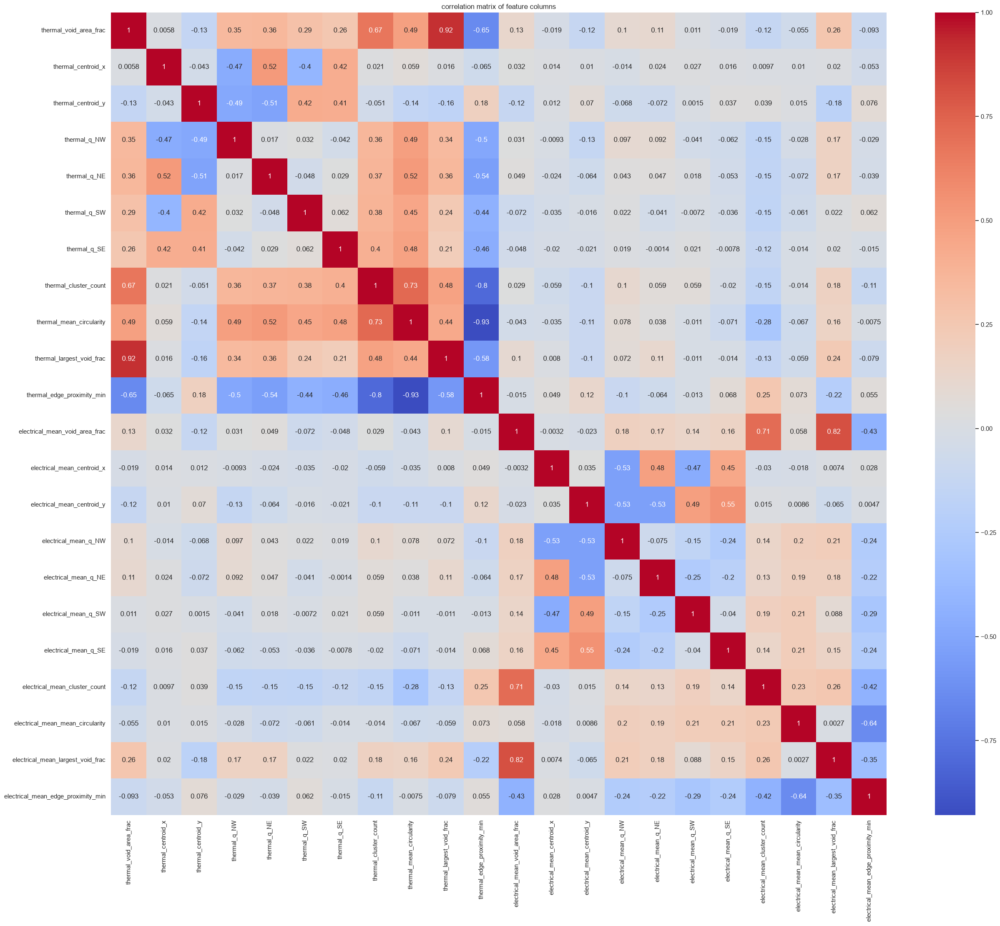

In [108]:
plt.figure(figsize=(30, 25))
sns.set(style='whitegrid')
sns.heatmap(data1[feat_cols].corr(numeric_only=True), annot=True, cbar=True, cmap='coolwarm')
plt.title('correlation matrix of feature columns')
plt.tight_layout
plt.show()

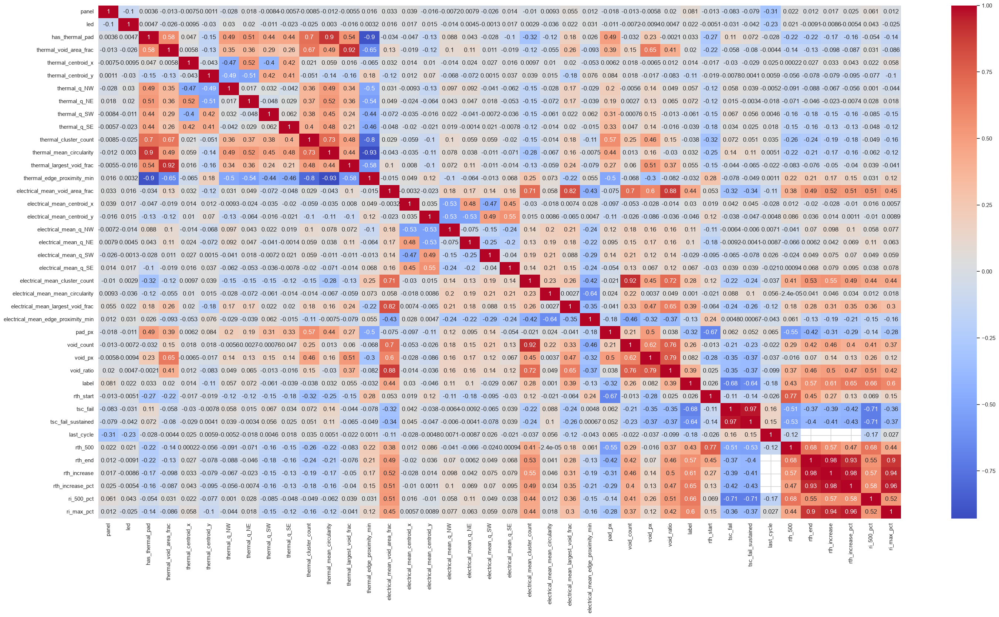

In [109]:
plt.figure(figsize=(35, 18))
sns.set(style='whitegrid')
sns.heatmap(data1.corr(numeric_only=True), annot=True, cbar=True, cmap='coolwarm')
plt.xticks()
plt.tight_layout
plt.show()

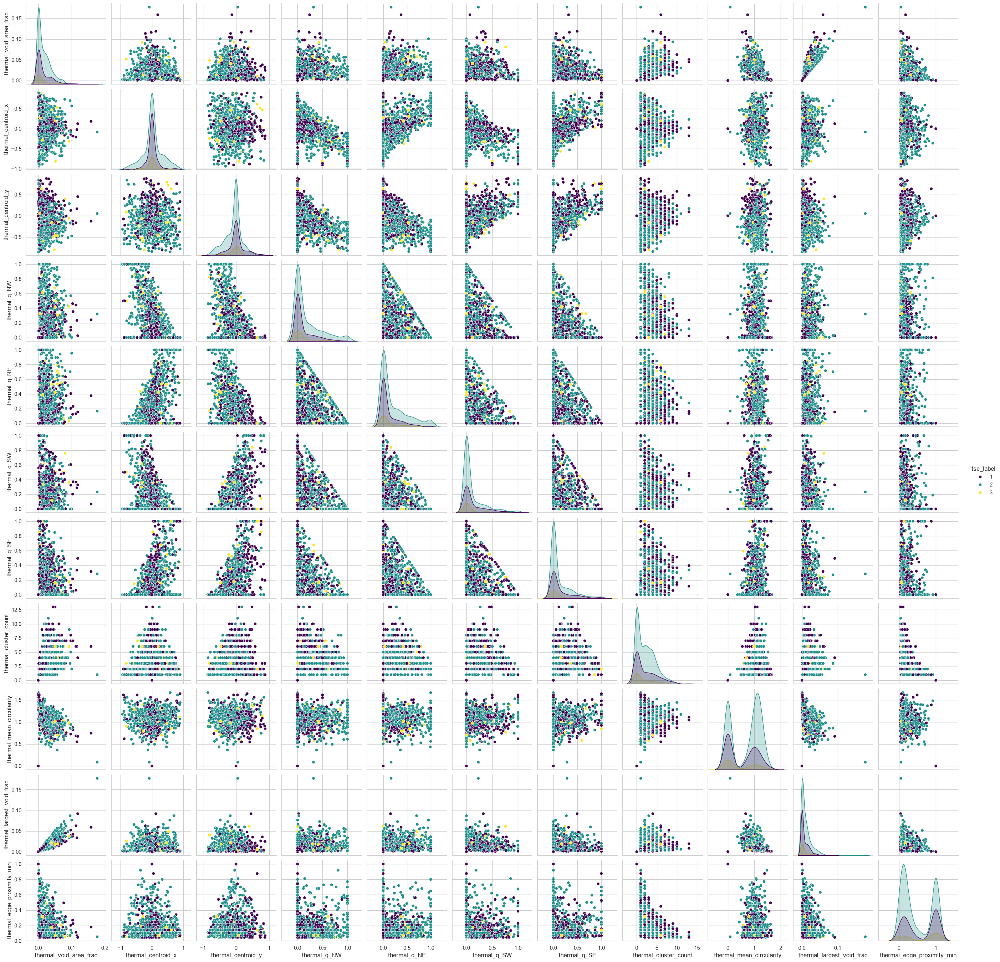

In [156]:
sns.pairplot(
    data=data1[thermal_cols + ['tsc_label']],
    hue='tsc_label',
    palette='viridis'
)
plt.show()
plt.show()

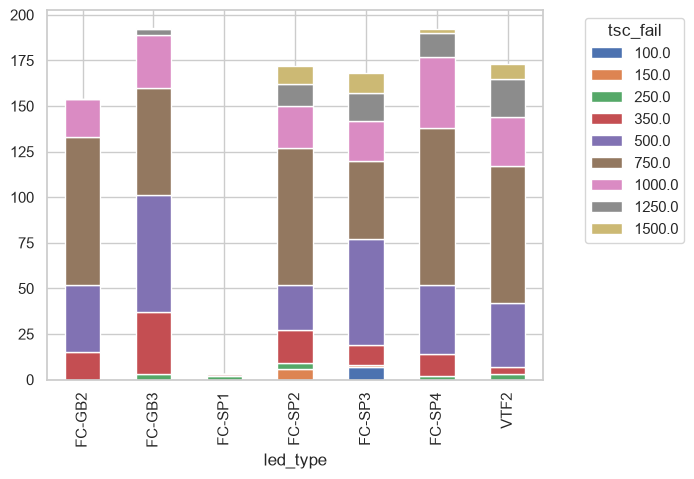

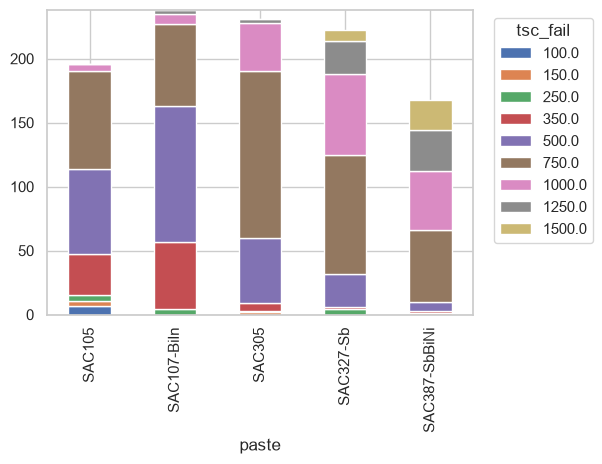

In [110]:
ax1 = pd.crosstab(data1["led_type"], data1[target_cls]).plot.bar(stacked=True)
ax2 = pd.crosstab(data1["paste"],    data1[target_cls]).plot.bar(stacked=True)
ax1.legend(title=target_cls, loc='upper right', bbox_to_anchor=(1.3, 1))
ax2.legend(title=target_cls, loc='upper right', bbox_to_anchor=(1.3, 1))
plt.tight_layout()


c:\Users\JPagtalu\Documents\Joanna\MEng AI\ai221\ai221_project\ai221_env\Lib\site-packages\pandas\core\arraylike.py:438: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


Text(0, 0.5, 'Frequency')

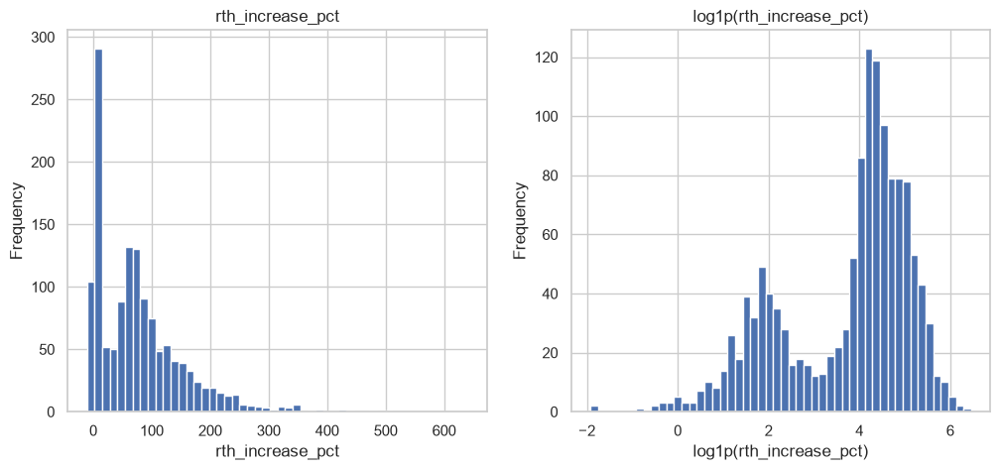

In [111]:
fig, ax = plt.subplots(1,2, figsize=(12, 5))
data1[target_reg].hist(bins=50, ax=ax[0])
ax[0].set_title("rth_increase_pct")
ax[0].set_xlabel('rth_increase_pct')
ax[0].set_ylabel('Frequency')


np.log1p(data1[target_reg]).hist(bins=50, ax=ax[1])
ax[1].set_title("log1p(rth_increase_pct)")
ax[1].set_xlabel('log1p(rth_increase_pct)')
ax[1].set_ylabel('Frequency')


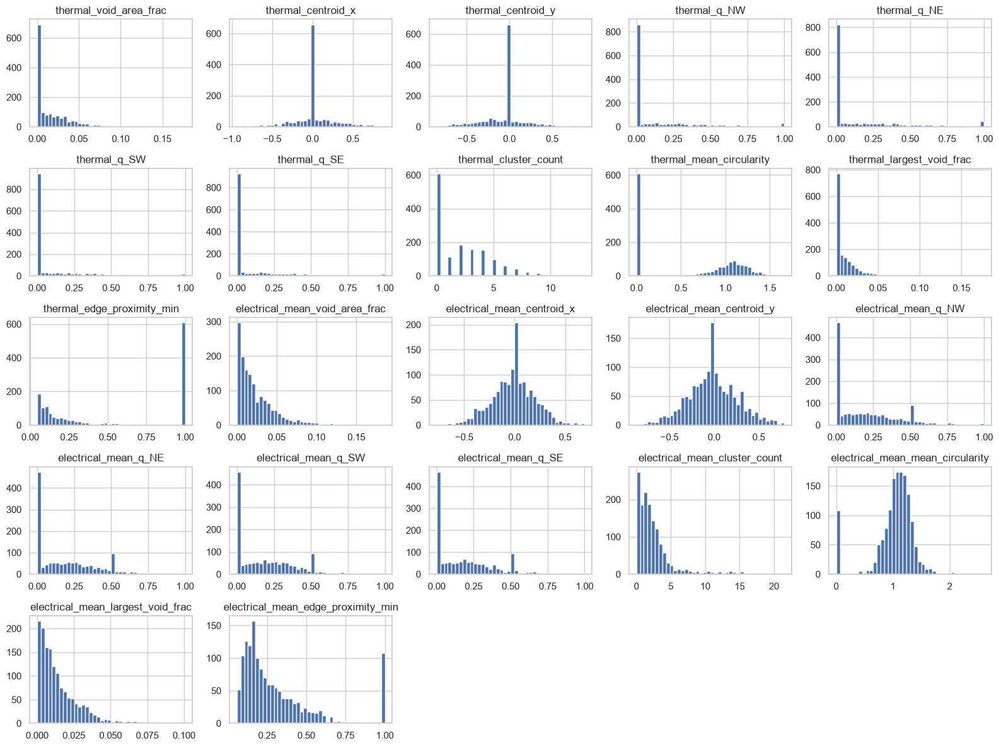

In [112]:
data1[feat_cols].hist(bins=40, figsize=(16, 12))
plt.tight_layout()

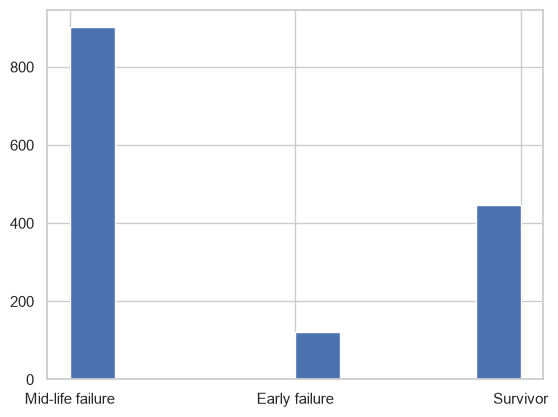

In [113]:
plt.hist(data1['label_name'])
plt.show()


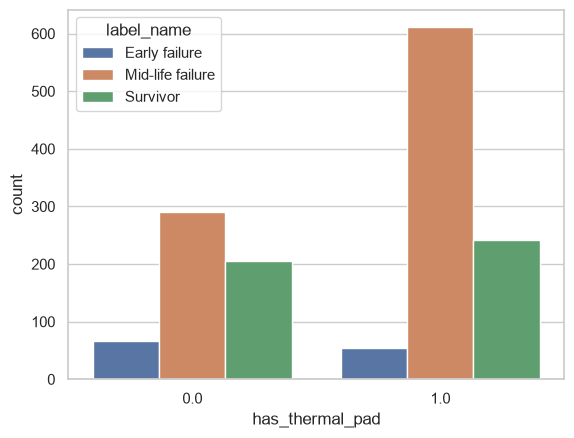

In [114]:
# plot the count of each label that survived per has_thermal_pad 
sns.countplot(data=data1, x='has_thermal_pad', hue='label_name')
plt.show()

# PCA

In [115]:
len(feat_cols)

22

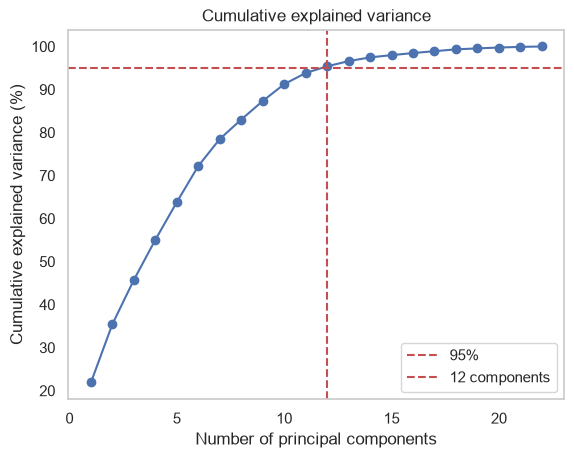

In [116]:
# there are cell without values in the dataset, use imputer
x = SimpleImputer(strategy='constant', fill_value=0).fit_transform(data1[feat_cols])
x_scaled = StandardScaler().fit_transform(x)
pca = PCA(n_components=len(feat_cols))
pca_result = pca.fit_transform(x_scaled)  # limit up to max number of feature cols lang

var = pca.explained_variance_ratio_
cpv = np.cumsum(var)*100
plt.plot(np.arange(cpv.size)+1, cpv, 'bo-')
plt.xlabel('Number of principal components')
plt.ylabel('Cumulative explained variance (%)')
plt.title('Cumulative explained variance')
plt.axhline(95, color='r', linestyle='--', label='95%')
plt.axvline(np.argmax(cpv >= 95) + 1, color='r', linestyle='--', label=f'{np.argmax(cpv >= 95) + 1} components')
plt.legend()
plt.grid(True)
plt.grid()
plt.show()



## Save PCA data into csv

In [117]:
# get only the 9% cpv in pca
pca_df = pd.DataFrame(pca_result[:, :12], columns=[f'PC{i+1}' for i in range(12)])
# pca_df['unit_id'] = data1['unit_id'].values  # just to make sure the data would not be scrambled
print(pca_df.shape)
pca_df.head()


(1470, 12)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12
0,-1.444234,-0.868894,0.130200,2.057712,1.276376,3.747145,1.830149,0.560130,-0.716537,-1.641526,-0.372666,-1.173486
1,-0.642568,-4.827283,0.100872,-0.574332,-2.034888,0.444822,-2.467271,-0.096554,-1.236669,0.182779,0.712882,-0.295435
2,-1.537161,-3.860671,0.230221,0.918780,2.453337,0.617330,-2.757435,0.655930,1.637199,-1.686399,0.637474,-1.245342
3,-0.195140,-1.681555,-0.829848,-3.609944,-1.782421,0.950935,-0.868081,-1.223561,0.438222,2.576707,-0.477238,-1.025622
4,0.102638,-4.696709,0.636778,-0.194927,0.287323,2.172015,-2.574431,-0.434225,-1.759488,-1.506269,0.365888,-0.966030


In [ ]:
# save pca_df into csv file


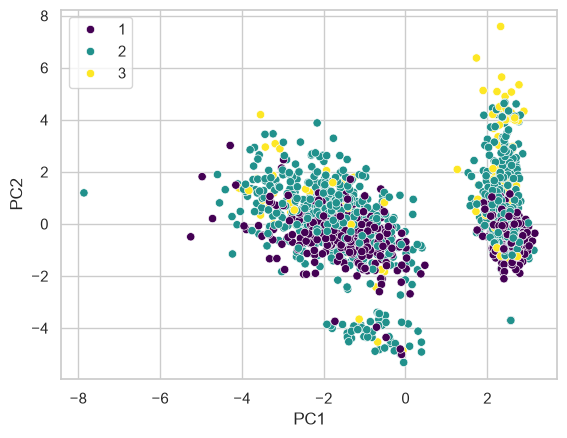

In [118]:
pca_labeled = pca_df.copy()
pca_labeled['label'] = data1['label'].values

#plot the first two principal components
sns.scatterplot(data=pca_labeled, x='PC1', y='PC2', hue='label', palette='viridis')
plt.legend()
plt.show()

In [119]:
pca_labeled.head()
    

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,label
0,-1.444234,-0.868894,0.130200,2.057712,1.276376,3.747145,1.830149,0.560130,-0.716537,-1.641526,-0.372666,-1.173486,2
1,-0.642568,-4.827283,0.100872,-0.574332,-2.034888,0.444822,-2.467271,-0.096554,-1.236669,0.182779,0.712882,-0.295435,2
2,-1.537161,-3.860671,0.230221,0.918780,2.453337,0.617330,-2.757435,0.655930,1.637199,-1.686399,0.637474,-1.245342,2
3,-0.195140,-1.681555,-0.829848,-3.609944,-1.782421,0.950935,-0.868081,-1.223561,0.438222,2.576707,-0.477238,-1.025622,2
4,0.102638,-4.696709,0.636778,-0.194927,0.287323,2.172015,-2.574431,-0.434225,-1.759488,-1.506269,0.365888,-0.966030,2


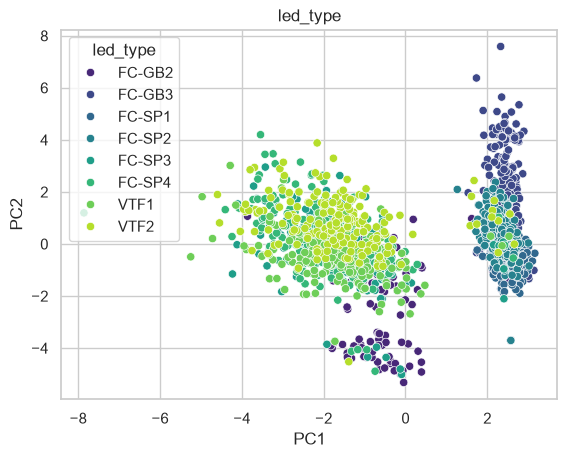

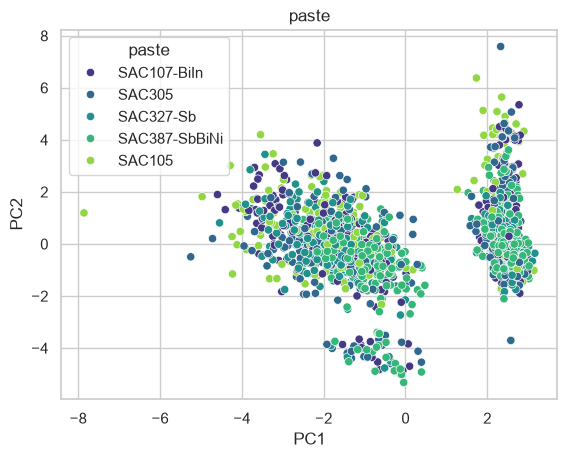

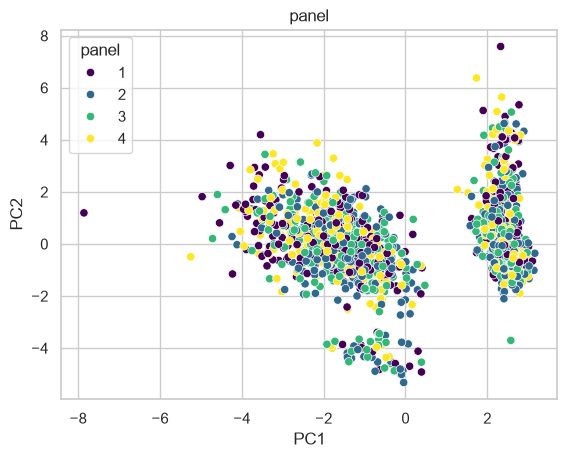

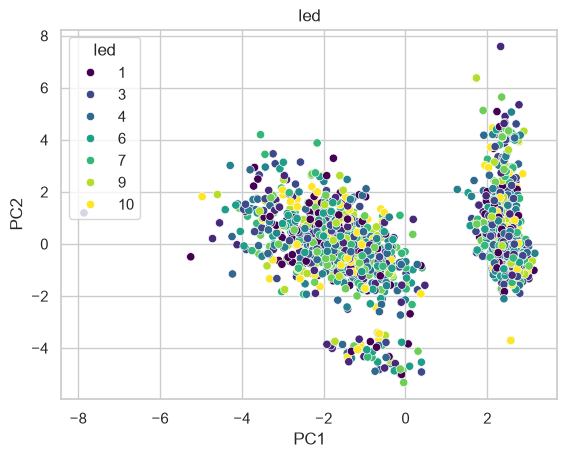

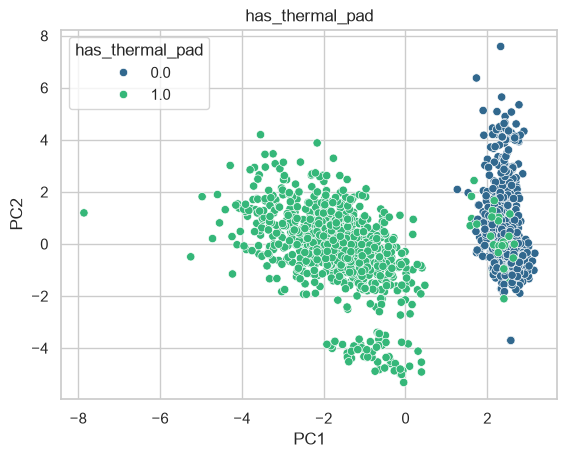

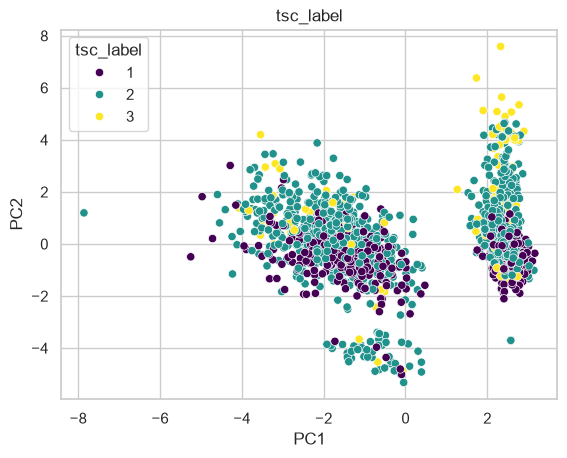

In [157]:
for col in ['led_type', 'paste', 'panel', 'led', 'has_thermal_pad', 'tsc_label']:
    sns.scatterplot(data=pca_labeled, x='PC1', y='PC2', hue=data1[col], palette='viridis')
    plt.title(col)
    plt.show()


# Kernel PCA

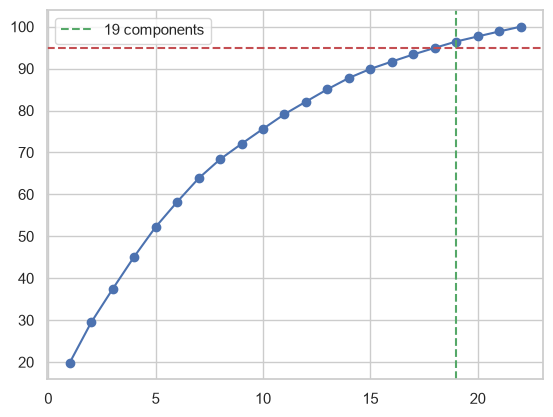

In [181]:
kpca = KernelPCA(n_components=len(feat_cols), kernel='rbf')
kpca_result = kpca.fit_transform(x_scaled)

kpca_evratio = kpca.eigenvalues_ / kpca.eigenvalues_.sum()
kpca_cpv = np.cumsum(kpca_evratio)*100
plt.plot(np.arange(kpca_cpv.size)+1, kpca_cpv, 'bo-')
plt.axhline(y=95, color='r', linestyle='--')
plt.axvline(x=np.argmax(kpca_cpv >= 95)+1, color='g', linestyle='--', label=f'{np.argmax(kpca_cpv >= 95)+1} components')
plt.legend()
plt.show()

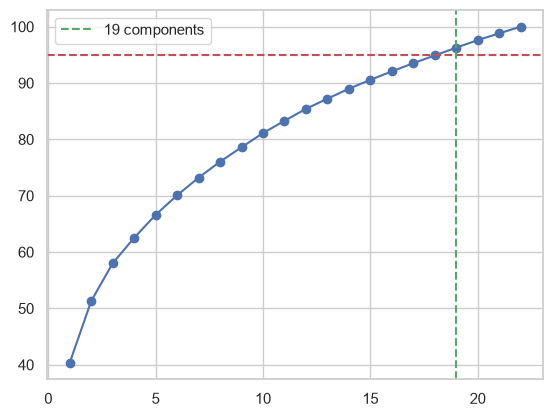

In [174]:
kpca = KernelPCA(n_components=len(feat_cols), kernel='poly', gamma= 1, degree = 3)
kpca_result = kpca.fit_transform(x_scaled)

kpca_evratio = kpca.eigenvalues_ / kpca.eigenvalues_.sum()
kpca_cpv = np.cumsum(kpca_evratio)*100
plt.plot(np.arange(kpca_cpv.size)+1, kpca_cpv, 'bo-')
plt.axhline(y=95, color='r', linestyle='--')
plt.axvline(x=np.argmax(kpca_cpv >= 95)+1, color='g', linestyle='--', label=f'{np.argmax(kpca_cpv >= 95)+1} components')
plt.legend()
plt.show()

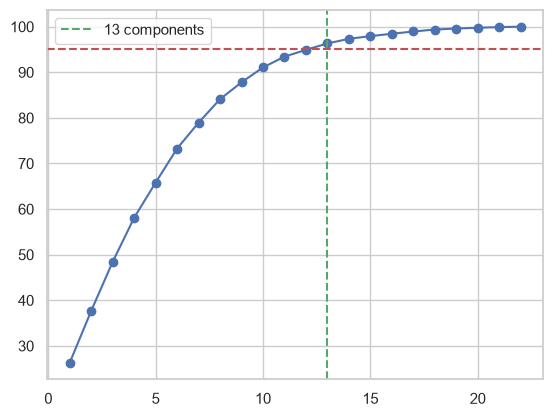

In [180]:
kpca = KernelPCA(n_components=len(feat_cols), kernel='cosine', gamma= 1/len(feat_cols), degree = 3)
kpca_result = kpca.fit_transform(x_scaled)

kpca_evratio = kpca.eigenvalues_ / kpca.eigenvalues_.sum()
kpca_cpv = np.cumsum(kpca_evratio)*100
plt.plot(np.arange(kpca_cpv.size)+1, kpca_cpv, 'bo-')
plt.axhline(y=95, color='r', linestyle='--')
plt.axvline(x=np.argmax(kpca_cpv >= 95)+1, color='g', linestyle='--', label=f'{np.argmax(kpca_cpv >= 95)+1} components')
plt.legend()
plt.show()

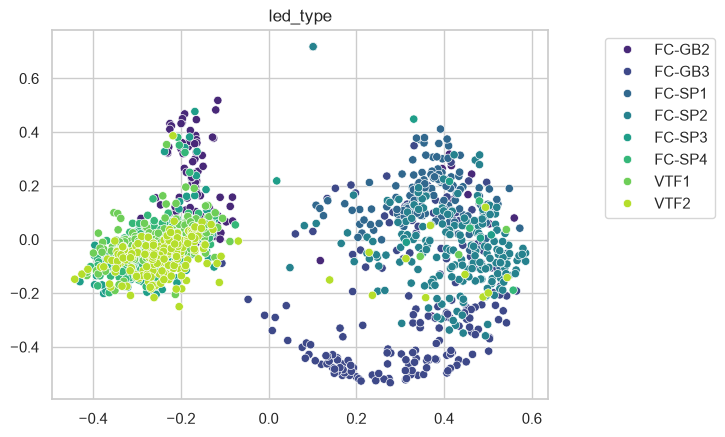

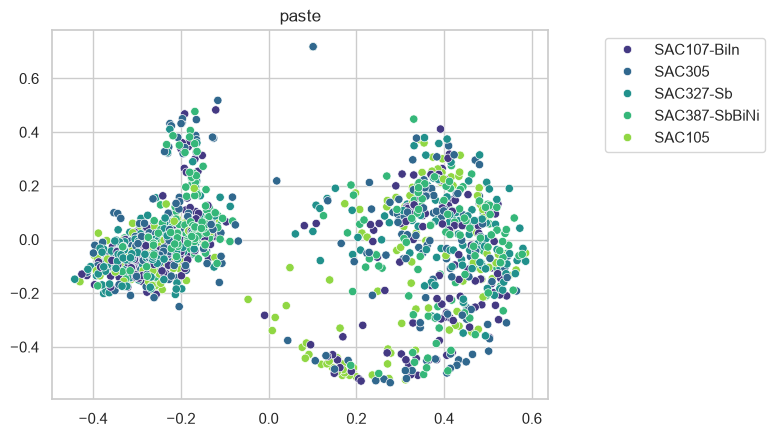

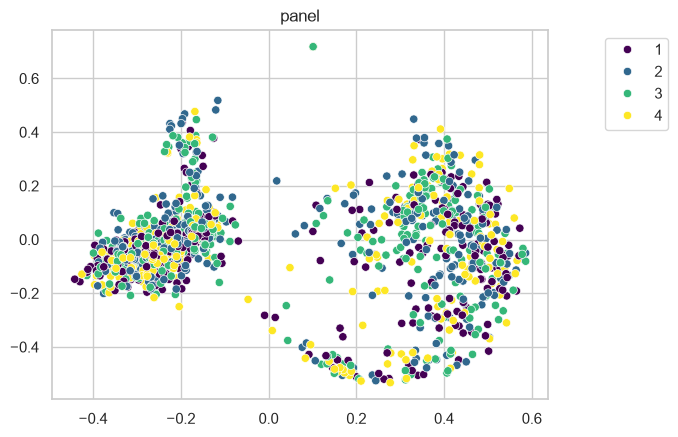

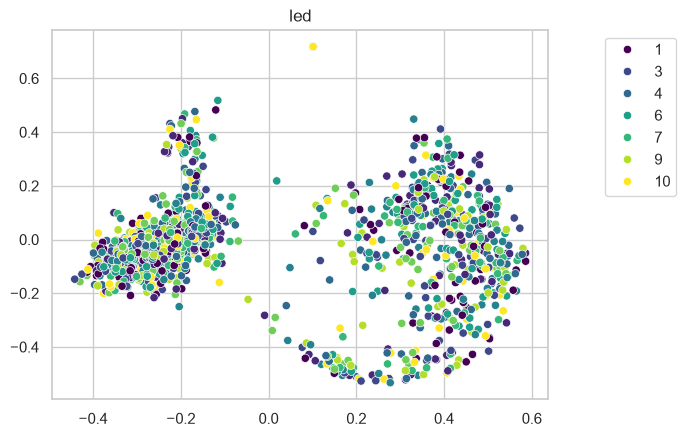

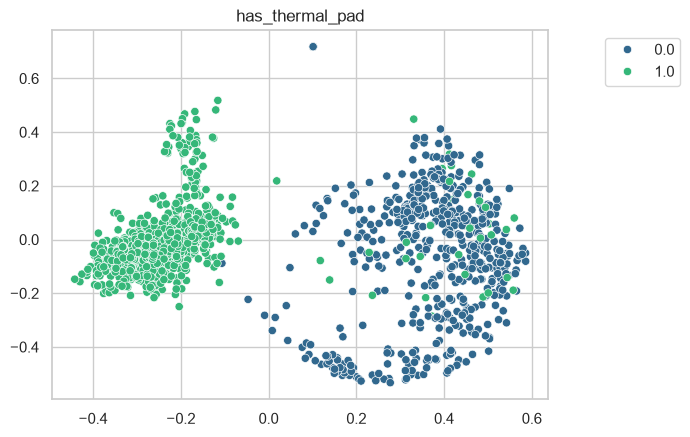

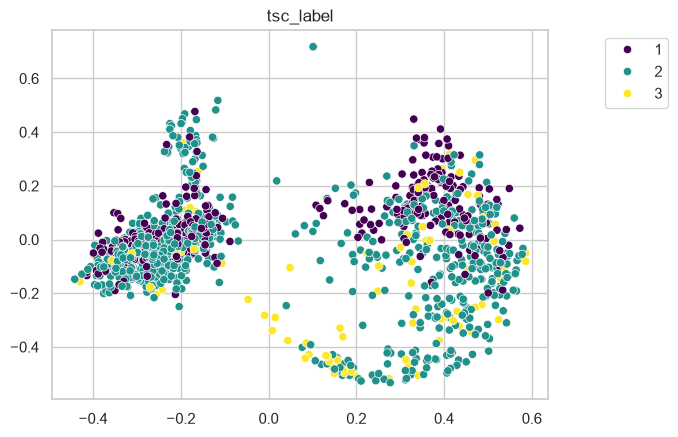

In [182]:
for col in ['led_type', 'paste', 'panel', 'led', 'has_thermal_pad', 'tsc_label']:
    sns.scatterplot(x=kpca_result[:, 0], y=kpca_result[:, 1], hue=data1[col], palette='viridis')
    plt.legend(bbox_to_anchor=(1.1, 1), loc='upper left')
    plt.title(col)
    plt.show()

# t-SNE

(1470, 2)


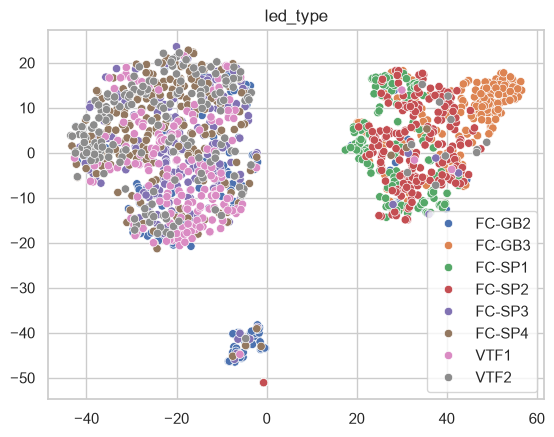

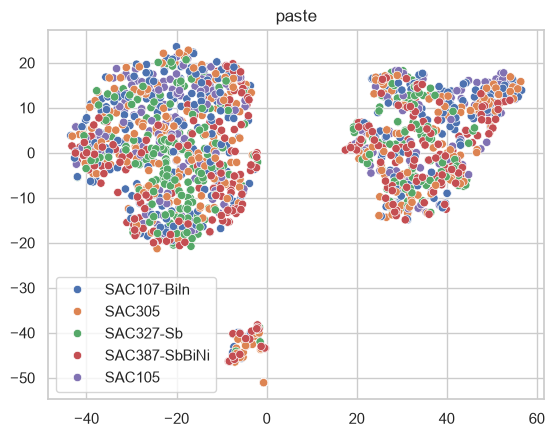

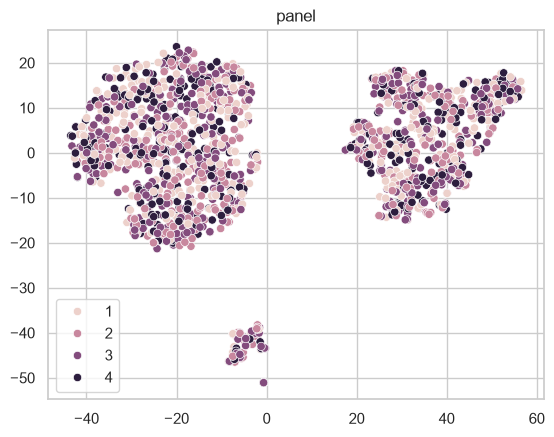

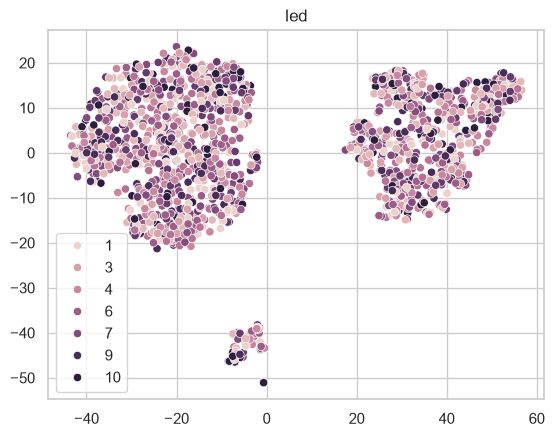

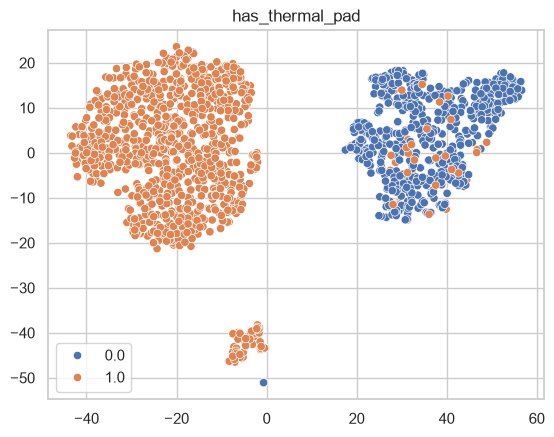

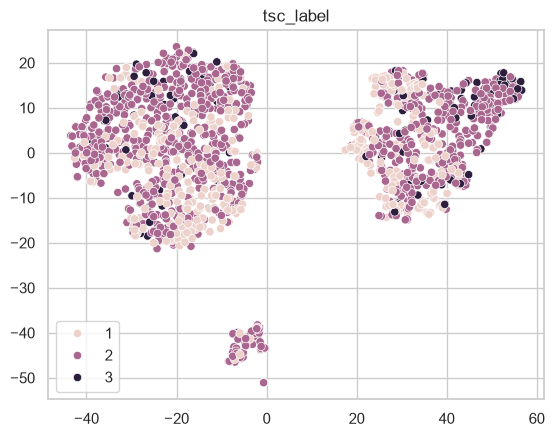

In [206]:
tsne = manifold.TSNE(n_components=2, perplexity=50, learning_rate='auto', max_iter=1000)
X_tsne = tsne.fit_transform(x_scaled)
print(X_tsne.shape)
for col in ['led_type', 'paste', 'panel', 'led', 'has_thermal_pad', 'tsc_label']:
    sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1], hue=data1[col])
    plt.legend()
    plt.title(col)
    plt.show()

# Isomap

c:\Users\JPagtalu\Documents\Joanna\MEng AI\ai221\ai221_project\ai221_env\Lib\site-packages\sklearn\manifold\_isomap.py:386: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
c:\Users\JPagtalu\Documents\Joanna\MEng AI\ai221\ai221_project\ai221_env\Lib\site-packages\scipy\sparse\_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


[[ -6.2809774    0.25416372]
 [ -7.18181316  -8.76406583]
 [-10.82501432  -6.54955568]
 ...
 [ -5.19547808   5.73967936]
 [ -6.60829732  -1.42811904]
 [ -8.40193829   0.28463433]]


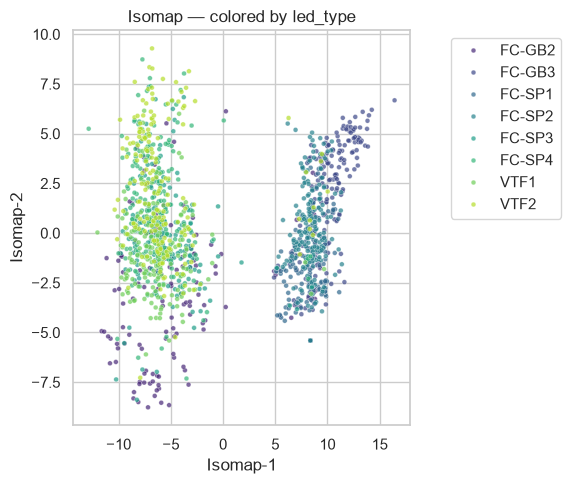

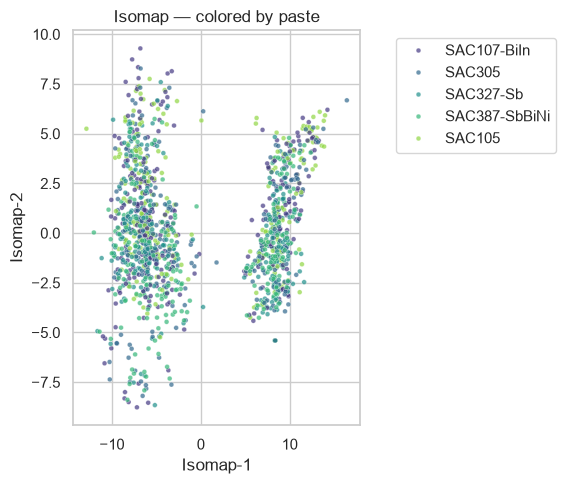

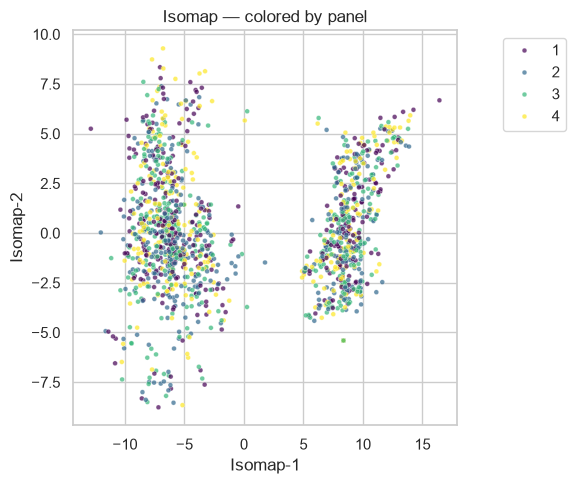

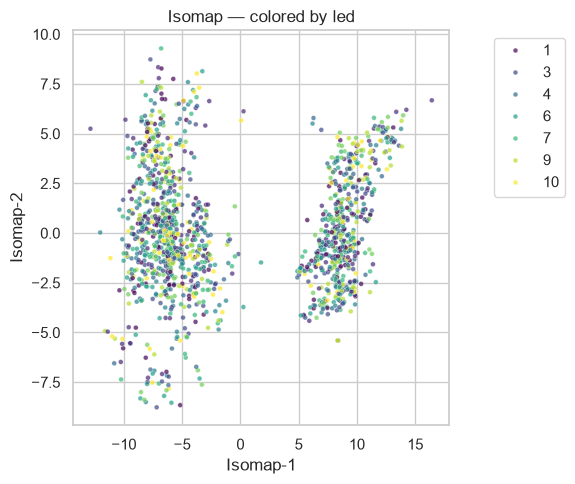

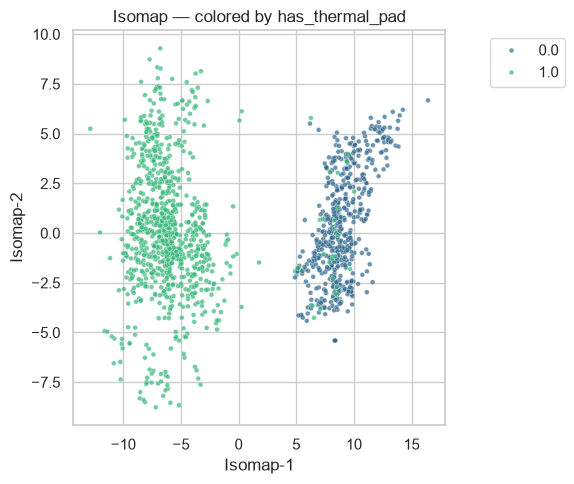

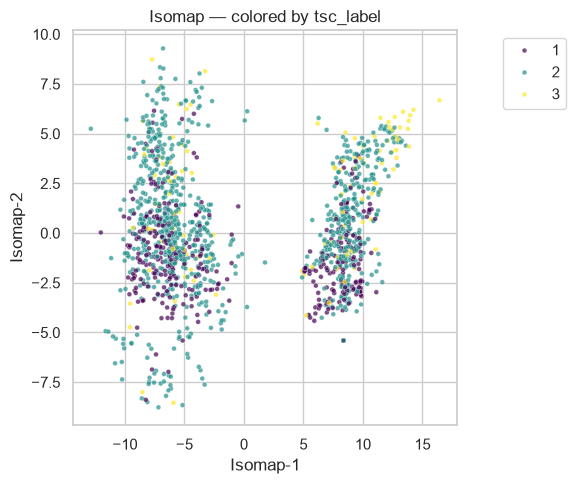

In [160]:
iso = manifold.Isomap(n_neighbors=20, n_components=2)
emb_iso = iso.fit_transform(x_scaled)
print(emb_iso)

for col in ['led_type', 'paste', 'panel', 'led', 'has_thermal_pad', 'tsc_label']:
    fig = plt.figure(figsize=(6, 5))
    ax = fig.add_subplot(111)
    sns.scatterplot(x=emb_iso[:, 0], y=emb_iso[:, 1], hue=data1[col], palette='viridis', s=12, alpha=0.7, ax=ax)
    ax.legend(bbox_to_anchor=(1.1, 1), loc='upper left')
    ax.set_xlabel("Isomap-1")
    ax.set_ylabel("Isomap-2")
    ax.set_title(f"Isomap — colored by {col}")
    plt.tight_layout()
    plt.show()

# UMAP

(1470, 2)


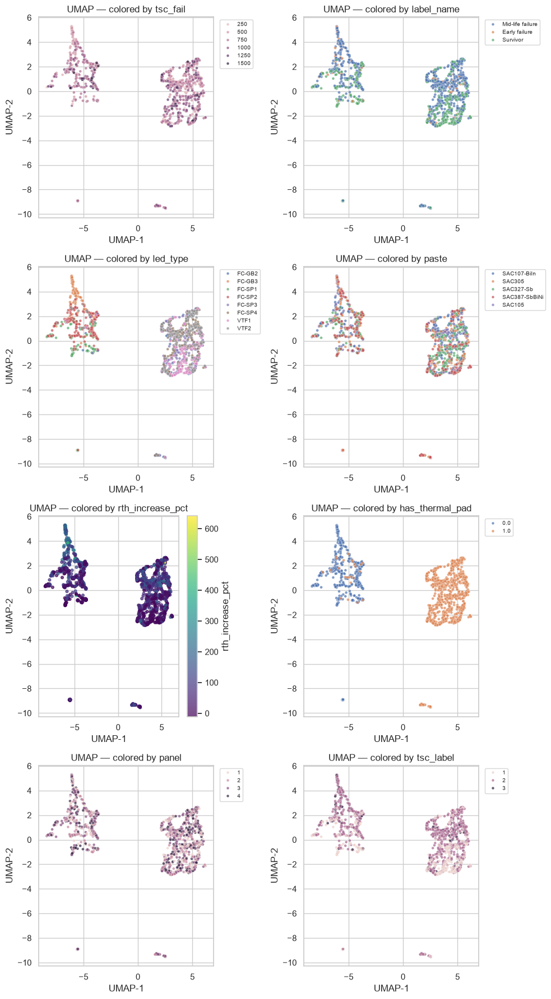

In [212]:
import umap

reducer = umap.UMAP(
    n_components=2,       # 2D for plotting
    n_neighbors=15,       # how "local" the manifold is (try 5, 15, 30, 50)
    min_dist=0.1,         # smaller = tighter clusters, better for DBSCAN
    metric="euclidean",   # default; "cosine" is another option for high-dim
    random_state=42, optimizer='adam'     # reproducibility
)
emb = reducer.fit_transform(x_scaled)   # shape (n_samples, 2)
print(emb.shape)

labels_to_try = {
    "tsc_fail":         "categorical",
    "label_name":       "categorical",
    "led_type":         "categorical",
    "paste":            "categorical",
    "rth_increase_pct": "continuous",
    'has_thermal_pad': "categorical",
    'panel':            "categorical",
    'tsc_label':        "categorical",
}

n = len(labels_to_try)
fig, axes = plt.subplots(4, 2, figsize=(5*2, 4.5*4), squeeze=False)
for ax, (lbl, kind) in zip(axes.flat, labels_to_try.items()):
    if kind == "continuous":
        sc = ax.scatter(emb[:, 0], emb[:, 1], c=data1[lbl], cmap="viridis", s=12, alpha=0.7)
        plt.colorbar(sc, ax=ax, label=lbl)
    else:
        sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=data1[lbl], ax=ax,
                        s=12, alpha=0.7, legend="brief")
        ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
    ax.set_title(f"UMAP — colored by {lbl}")
    ax.set_xlabel("UMAP-1"); ax.set_ylabel("UMAP-2")
plt.tight_layout()
plt.show()

(1470, 3)


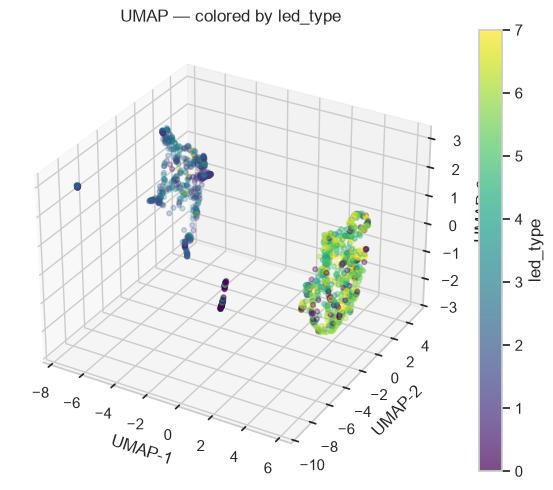

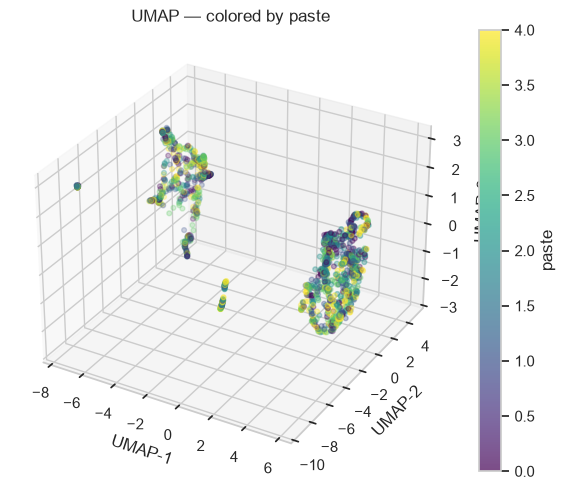

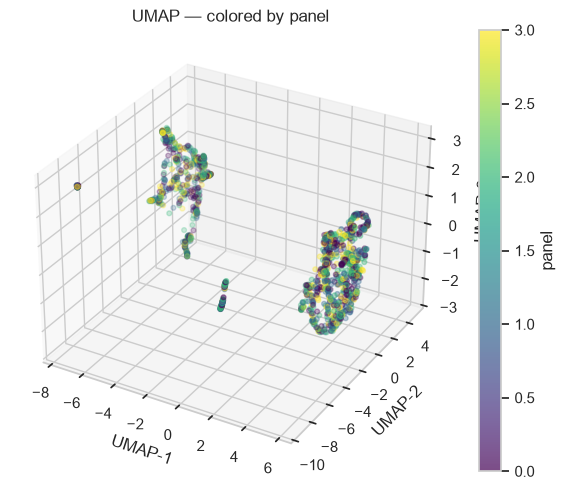

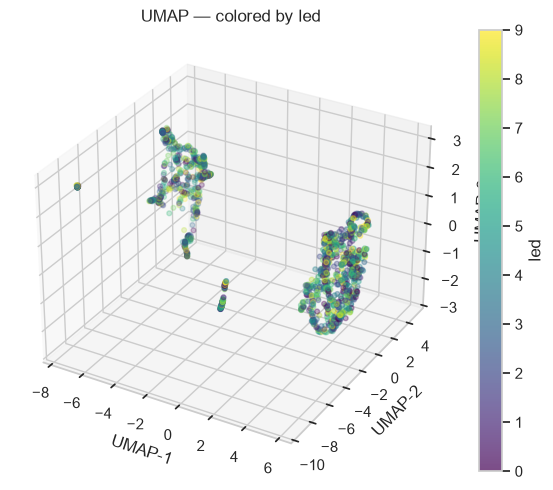

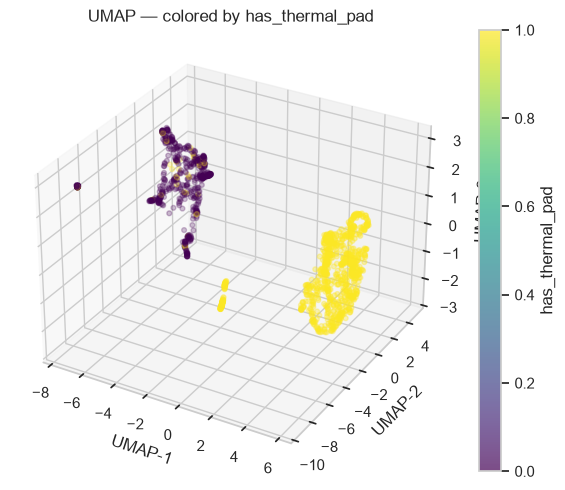

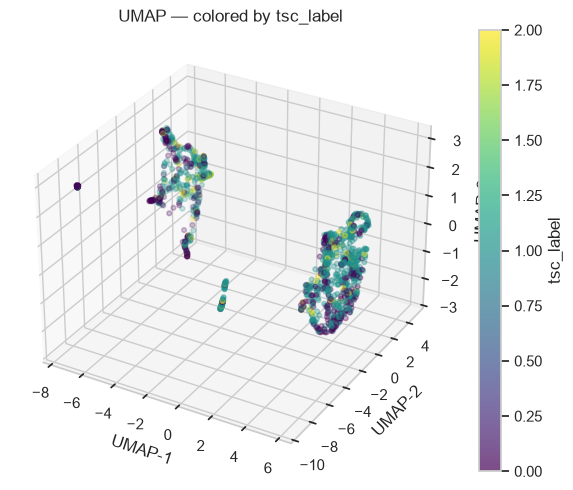

In [163]:
# 3D plotting of Umap
reducer_3d = umap.UMAP(
    n_components=3,
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=42,
    optimizer='adam'
)
emb_3d = reducer_3d.fit_transform(x_scaled)
print(emb_3d.shape)

for col in ['led_type', 'paste', 'panel', 'led', 'has_thermal_pad', 'tsc_label']:
    fig = plt.figure(figsize=(6, 5))
    ax = fig.add_subplot(111, projection='3d')
    scatter = ax.scatter(emb_3d[:, 0], emb_3d[:, 1], emb_3d[:, 2], c=pd.Categorical(data1[col]).codes, cmap='viridis', s=12, alpha=0.7)
    fig.colorbar(scatter, ax=ax, label=col)
    ax.set_xlabel("UMAP-1")
    ax.set_ylabel("UMAP-2")
    ax.set_zlabel("UMAP-3")
    ax.set_title(f"UMAP — colored by {col}")
    plt.tight_layout()
    plt.show()

c:\Users\JPagtalu\Documents\Joanna\MEng AI\ai221\ai221_project\ai221_env\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\JPagtalu\Documents\Joanna\MEng AI\ai221\ai221_project\ai221_env\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\JPagtalu\Documents\Joanna\MEng AI\ai221\ai221_project\ai221_env\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout wa

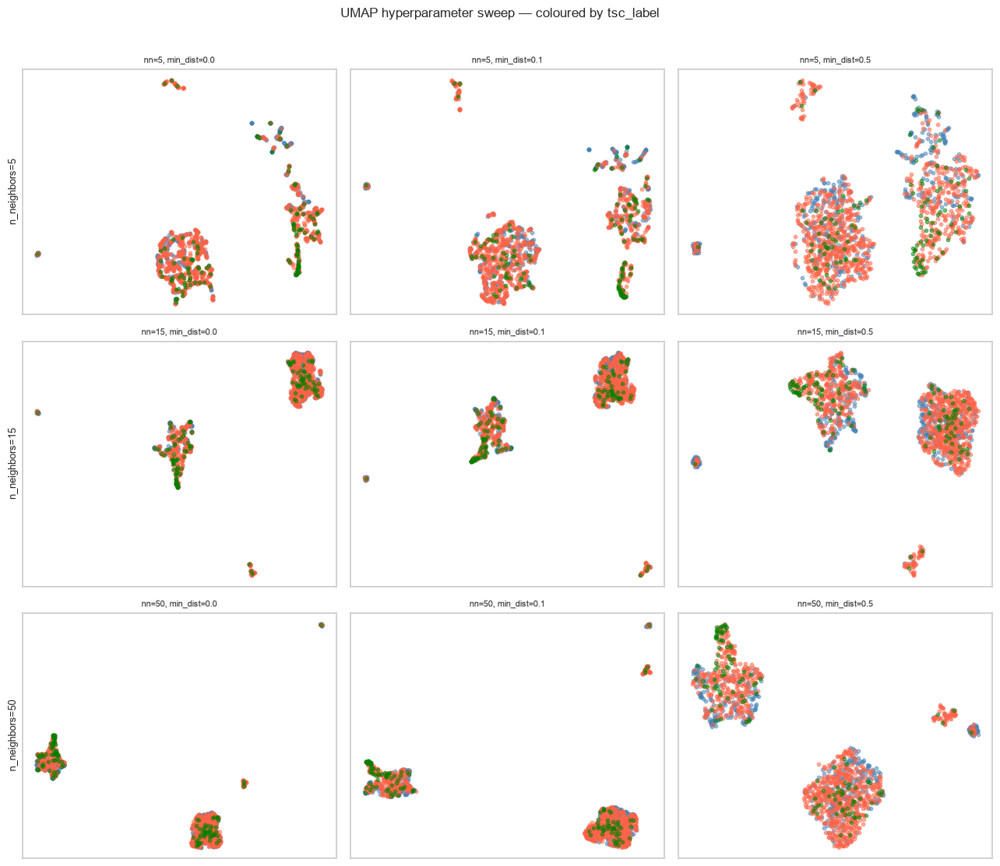

In [211]:
n_neighbors_grid = [5, 15, 50]
min_dist_grid = [0.0, 0.1, 0.5]

fig, axes = plt.subplots(
    len(n_neighbors_grid), len(min_dist_grid),
    figsize=(13, 11),
    squeeze=False,
)

for row_i, nn in enumerate(n_neighbors_grid):
    for col_i, md in enumerate(min_dist_grid):
        # t0 = time.perf_counter()
        emb = umap.UMAP(
            n_components=2,
            n_neighbors=nn,
            min_dist=md,
            random_state=42,
        ).fit_transform(x_scaled)
        # elapsed = time.perf_counter() - t0

        ax = axes[row_i][col_i]
        for val, colour in {1: "steelblue", 2: "tomato", 3: "green"}.items():
            mask = data1["tsc_label"] == val
            ax.scatter(emb[mask, 0], emb[mask, 1], c=colour, s=10, alpha=0.5)
        ax.set_title(
            f"nn={nn}, min_dist={md}",
            fontsize=8,
        )
        ax.set_xticks([])
        ax.set_yticks([])

    axes[row_i][0].set_ylabel(f"n_neighbors={nn}", fontsize=9)

fig.suptitle(
    "UMAP hyperparameter sweep — coloured by tsc_label",
    fontsize=12, y=1.01,
)
plt.tight_layout()
plt.show()

## extract the mixing rows

In [126]:
# extract rows where has_thermal_pad == 1 from umap, mixing in has_thermal_pad == 0 samples

index = []

for i, (x, y) in enumerate(emb):
    if x < 0 and data1.iloc[i]['has_thermal_pad'] == 1:
        # check if the sample has a thermal pad
        index.append(i)

print(index)
# show the rows of data1 with indices in index
mixing_data = pd.DataFrame(data1.iloc[index])
data1.iloc[index]


[12, 17, 22, 25, 30, 31, 34, 77, 79, 113, 114, 119, 123, 129, 130, 135, 136, 137, 142, 143, 144, 148, 149, 150, 153, 884, 885, 886, 887, 902, 1066, 1082, 1098, 1147, 1261, 1265, 1294, 1302, 1362, 1370, 1372, 1373, 1385, 1452, 1454, 1456, 1465]


,unit_id,led_type,paste,panel,led,has_thermal_pad,thermal_void_area_frac,thermal_centroid_x,thermal_centroid_y,thermal_q_NW,...,label_status,tsc_fail,tsc_fail_sustained,last_cycle,rth_500,rth_end,rth_increase,rth_increase_pct,ri_500_pct,ri_max_pct
12,FC-GB2_SAC107-BiIn_P2_L04,FC-GB2,SAC107-BiIn,2,4,1.0,0.0,0.0,0.0,0.0,...,ok,350.0,350.0,1500.0,18.562644,51.803846,42.208252,439.871159,93.449651,439.871159
17,FC-GB2_SAC107-BiIn_P2_L09,FC-GB2,SAC107-BiIn,2,9,1.0,0.0,0.0,0.0,0.0,...,ok,500.0,500.0,1500.0,12.192808,16.918301,7.057916,71.578501,23.654487,71.578501
22,FC-GB2_SAC107-BiIn_P3_L04,FC-GB2,SAC107-BiIn,3,4,1.0,0.0,0.0,0.0,0.0,...,ok,750.0,750.0,1500.0,11.275019,14.505770,4.941077,51.659550,17.881665,51.659550
25,FC-GB2_SAC107-BiIn_P3_L07,FC-GB2,SAC107-BiIn,3,7,1.0,0.0,0.0,0.0,0.0,...,ok,500.0,500.0,1500.0,13.430793,17.087928,7.721526,82.438543,43.393297,82.438543
30,FC-GB2_SAC107-BiIn_P4_L02,FC-GB2,SAC107-BiIn,4,2,1.0,0.0,0.0,0.0,0.0,...,ok,350.0,350.0,1250.0,13.079594,NaN,NaN,NaN,44.162574,100.953231
31,FC-GB2_SAC107-BiIn_P4_L03,FC-GB2,SAC107-BiIn,4,3,1.0,0.0,0.0,0.0,0.0,...,ok,350.0,350.0,1500.0,12.669676,15.505957,6.390696,70.109848,38.994111,70.109848
34,FC-GB2_SAC107-BiIn_P4_L06,FC-GB2,SAC107-BiIn,4,6,1.0,0.0,0.0,0.0,0.0,...,ok,350.0,350.0,1500.0,13.795236,27.282324,18.189562,200.044416,51.716679,200.044416
77,FC-GB2_SAC327-Sb_P1_L01,FC-GB2,SAC327-Sb,1,1,1.0,0.0,0.0,0.0,0.0,...,ok,750.0,750.0,1500.0,10.887256,15.387800,5.942160,62.909027,15.262236,128.168751
79,FC-GB2_SAC327-Sb_P1_L03,FC-GB2,SAC327-Sb,1,3,1.0,0.0,0.0,0.0,0.0,...,ok,750.0,750.0,1500.0,10.334702,17.021786,7.753930,83.664765,11.511251,83.664765
113,FC-GB2_SAC327-Sb_P4_L07,FC-GB2,SAC327-Sb,4,7,1.0,0.0,0.0,0.0,0.0,...,ok,1000.0,1000.0,1000.0,10.252319,NaN,NaN,NaN,11.306872,47.411751


<Axes: xlabel='label_name'>

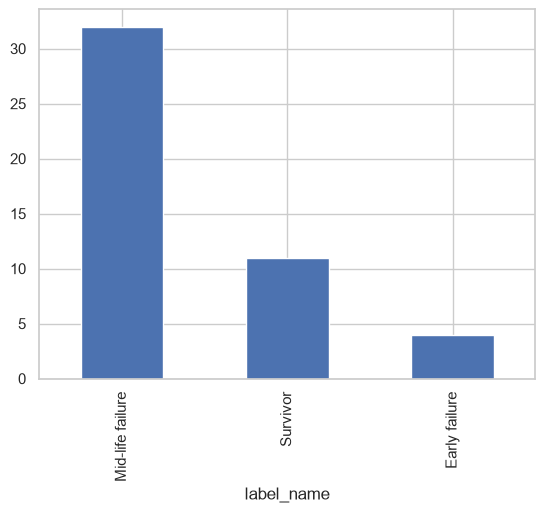

In [127]:
# plot the label_name
mixing_data['label_name'].value_counts().plot(kind='bar')

# K-Means + PCA

In [128]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score

Silhouette Score: 0.23093457755547694
Inertia: 20088.569401434757
Centroids: [[-2.05338344  0.55845744 -0.42270682  0.17725377  0.5249981  -0.86673925
   0.17815884 -0.06527177 -0.04029168 -0.01284674 -0.07739592 -0.08129485]
 [ 2.41912071  0.66438984 -0.11201658 -0.02147387 -0.04620546  0.05627039
   0.15663651  0.06948069  0.24529812 -0.05684913 -0.05631437  0.0952705 ]
 [-1.43890936 -0.56553921  0.92831279 -0.28488001 -0.78213819  1.25173705
   0.24784656 -0.05278556 -0.25580503  0.15146033  0.01664795 -0.0345015 ]
 [ 0.85463823 -3.97774581 -0.61232944  0.27437115  0.52490061 -0.6363776
  -2.35968555  0.08805848 -0.27234371 -0.13896262  0.56516294 -0.03574634]]


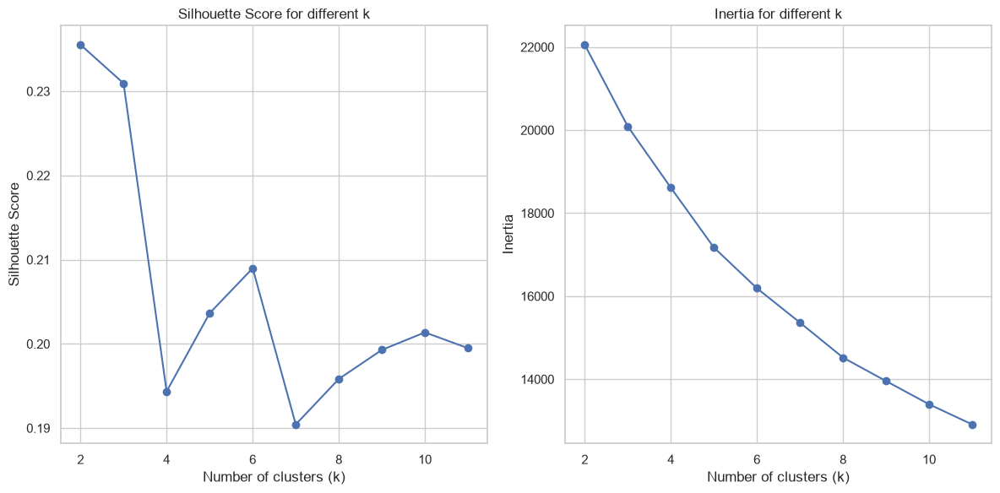

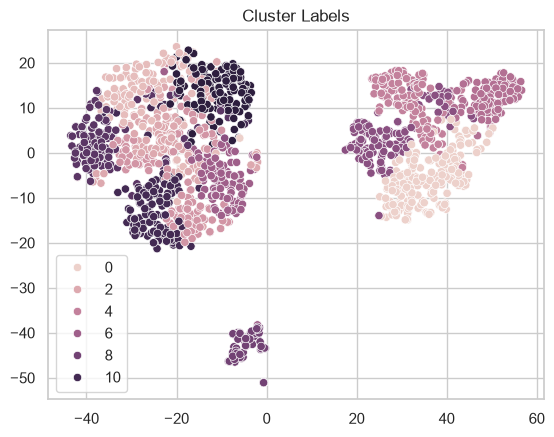

In [244]:
k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(pca_df)
centroids = kmeans.cluster_centers_
inertia = kmeans.inertia_
silhouette_values = silhouette_samples(pca_df, cluster_labels)
silhouette_avg = silhouette_score(pca_df, cluster_labels)
print("Silhouette Score:", silhouette_avg)
print("Inertia:", inertia)
print("Centroids:", centroids)


# optimize the k
inertia = []
silhouette =[]

for i in range(2, 12):
    kmeans = KMeans(n_clusters=i+1, random_state = 42, n_init=10)
    cluster_labels = kmeans.fit_predict(pca_df)
    silhouette_score_val = silhouette_score(pca_df, cluster_labels)
    inertia_score = kmeans.inertia_

    silhouette.append(silhouette_score_val)
    inertia.append(inertia_score)

# plot silhouette score and inertia for each k

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].plot(range(2, 12), silhouette, marker='o')
ax[0].set_title('Silhouette Score for different k')
ax[0].set_xlabel('Number of clusters (k)')
ax[0].set_ylabel('Silhouette Score')

ax[1].plot(range(2, 12), inertia, marker='o')
ax[1].set_title('Inertia for different k')
ax[1].set_xlabel('Number of clusters (k)')
ax[1].set_ylabel('Inertia')

plt.tight_layout()
plt.show()



# Visualize the clusters using t-SNE
tsne = manifold.TSNE(n_components=2, perplexity=50, learning_rate='auto', max_iter=1000)
X_tsne = tsne.fit_transform(x_scaled)
sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1], hue=cluster_labels)
plt.legend()
plt.title("Cluster Labels")
plt.show()

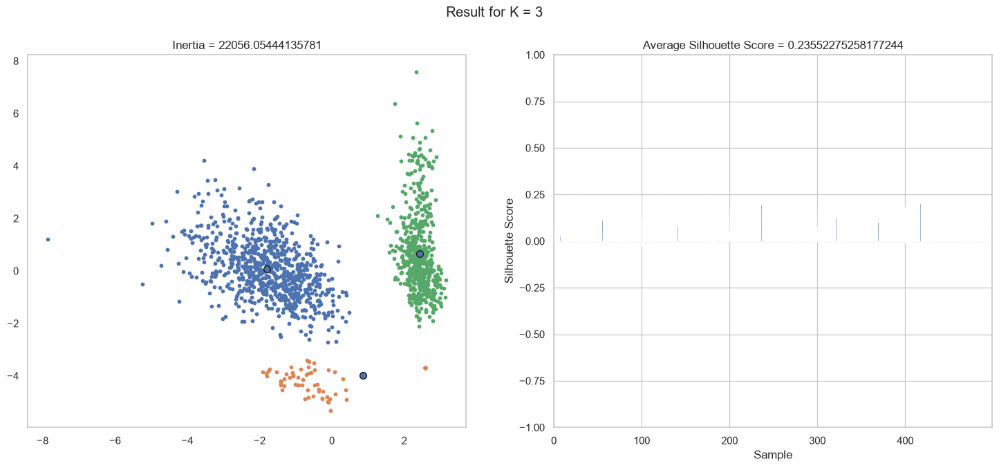

In [248]:
# x_scaled = StandardScaler().fit_transform(x)

k = 3
kmeans = KMeans(n_clusters=k, random_state=0, n_init=10)
kmeans.fit_transform(pca_df)
cluster_labels = kmeans.labels_
centroids = kmeans.cluster_centers_
inertia = kmeans.inertia_
silhouette_values = silhouette_samples(pca_df, cluster_labels)
silhouette_avg = silhouette_score(pca_df, cluster_labels)

fig, (ax1, ax2) = plt.subplots(1, 2)
fig.set_size_inches(18, 7)
fig.suptitle(f"Result for K = {k}")
for i in range(0,k):
    ax1.scatter(pca_df.iloc[cluster_labels == i,0], pca_df.iloc[cluster_labels == i,1], s=10)
ax1.scatter(centroids[:,0],centroids[:,1], s=50, color='b', edgecolor='k')
ax1.set_title(f"Inertia = {inertia}")
ax1.grid()
sample = 0
for i in range(0,k):
    sil = silhouette_values[cluster_labels == i]
    ax2.bar(np.arange(sample,sample + sil.size),sil)
    sample = sample + sil.size
ax2.axis([0, 499, -1, 1])
ax2.set_xlabel('Sample')
ax2.set_ylabel('Silhouette Score')
ax2.set_title(f"Average Silhouette Score = {silhouette_avg}")
plt.show()

# inertia_values = []
# silhouette_avgs = []
# fig2 = plt.figure(figsize=(20,20))
# for i in range(2,11):
#     kmeans = KMeans(n_clusters=i, n_init=10).fit(pca_df)
#     cluster_labels = kmeans.labels_
#     centroids = kmeans.cluster_centers_
#     inertia_values.append(kmeans.inertia_)
#     silhouette_avg = silhouette_score(pca_df, cluster_labels)
#     silhouette_avgs.append(silhouette_avg)
#     ax = fig2.add_subplot(330 + i - 1)
#     for j in range(0,i):
#         ax.scatter(pca_df.iloc[cluster_labels == j,0], pca_df.iloc[cluster_labels == j,1], s=10, alpha=0.3)
#     ax.scatter(centroids[:,0],centroids[:,1], s=50, color='b', edgecolor='k')
#     ax.set_title(f"Inertia = {kmeans.inertia_}\nSilhouette Score = {silhouette_avg}")

## Checking the the Kmeans cluster in t-SNE

1470
(1470, 2)


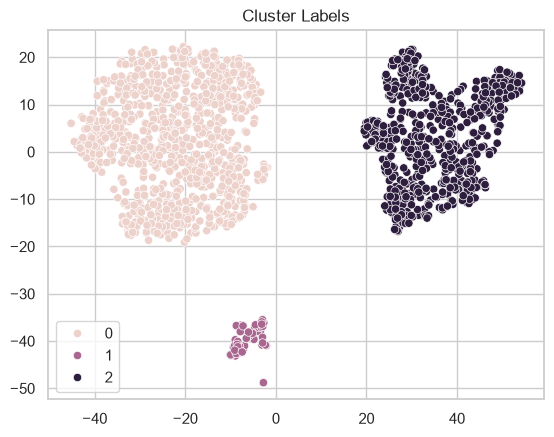

In [249]:
print(len(cluster_labels))

tsne = manifold.TSNE(n_components=2, perplexity=50, learning_rate='auto', max_iter=1000)
X_tsne = tsne.fit_transform(pca_df)
print(X_tsne.shape)
# for col in cluster_labels:
sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1], hue=cluster_labels)
plt.legend()
plt.title("Cluster Labels")
plt.show()

# Trying out to separate the has thermal pads without the thermal pads

In [130]:
thermal_pad_indices = []

for i in range(len(data1)):
    # print(i)
    if data1['has_thermal_pad'].iloc[i] == 1:
        thermal_pad_indices.append(i)

therm_df = pd.DataFrame(data1.iloc[thermal_pad_indices])
therm_df

,unit_id,led_type,paste,panel,led,has_thermal_pad,thermal_void_area_frac,thermal_centroid_x,thermal_centroid_y,thermal_q_NW,...,label_status,tsc_fail,tsc_fail_sustained,last_cycle,rth_500,rth_end,rth_increase,rth_increase_pct,ri_500_pct,ri_max_pct
0,FC-GB2_SAC107-BiIn_P1_L02,FC-GB2,SAC107-BiIn,1,2,1.0,0.020928,0.615373,0.072432,0.000000,...,ok,500.0,500.0,1500.0,12.084356,29.839828,20.264891,211.645181,26.208211,211.645181
1,FC-GB2_SAC107-BiIn_P1_L03,FC-GB2,SAC107-BiIn,1,3,1.0,0.010285,-0.529327,0.457574,0.174419,...,ok,750.0,750.0,1500.0,10.744296,16.605415,7.029735,73.412388,12.204009,73.412388
2,FC-GB2_SAC107-BiIn_P1_L04,FC-GB2,SAC107-BiIn,1,4,1.0,0.045802,0.497724,0.012773,0.000000,...,ok,750.0,750.0,1500.0,9.556831,14.151400,4.538046,47.205646,-0.587963,47.205646
3,FC-GB2_SAC107-BiIn_P1_L05,FC-GB2,SAC107-BiIn,1,5,1.0,0.004186,-0.166625,0.228571,0.000000,...,ok,500.0,500.0,1500.0,11.691541,16.517620,6.980075,73.185239,22.584383,73.185239
4,FC-GB2_SAC107-BiIn_P1_L06,FC-GB2,SAC107-BiIn,1,6,1.0,0.002511,0.026549,0.486486,0.000000,...,ok,500.0,500.0,1500.0,12.173268,17.237209,7.815018,82.942673,29.197835,82.942673
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,VTF2_SAC387-SbBiNi_P4_L02,VTF2,SAC387-SbBiNi,4,2,1.0,0.000000,0.000000,0.000000,0.000000,...,ok,NaN,NaN,1500.0,8.824649,9.992553,1.497410,17.626664,3.878763,17.626664
1466,VTF2_SAC387-SbBiNi_P4_L03,VTF2,SAC387-SbBiNi,4,3,1.0,0.004758,0.106992,0.280702,0.000000,...,ok,NaN,NaN,1500.0,8.612607,9.497589,1.214736,14.665678,3.981172,14.665678
1467,VTF2_SAC387-SbBiNi_P4_L04,VTF2,SAC387-SbBiNi,4,4,1.0,0.011448,0.676425,-0.235361,0.000000,...,ok,NaN,NaN,1500.0,8.600578,9.307966,1.014751,12.235925,3.706202,12.235925
1468,VTF2_SAC387-SbBiNi_P4_L05,VTF2,SAC387-SbBiNi,4,5,1.0,0.037615,-0.465130,-0.006172,0.237154,...,ok,1000.0,1000.0,1500.0,8.871979,16.159480,7.923641,96.209278,7.724045,96.209278


In [131]:
th_features = [c for c in therm_df.columns if c.startswith("thermal_")]
x_th = therm_df[th_features]

x_th_scaled = StandardScaler().fit_transform(x_th)
# x_th
x_th_scaled

array([[-0.23193956,  1.65381572,  0.46974255, ...,  0.56395421,
         0.25880009, -0.51053548],
       [-0.70571691, -1.56530192,  1.64485596, ...,  0.86069577,
        -0.70255607, -0.6254635 ],
       [ 0.87531537,  1.32296434,  0.28771302, ..., -0.61945063,
         2.02929768,  0.98352883],
       ...,
       [-0.65392553,  1.82550666, -0.46937312, ...,  0.42450547,
        -0.50119441, -0.07501876],
       [ 0.5108715 , -1.38476832,  0.2299122 , ..., -0.19561606,
         0.98283544, -0.37342836],
       [-0.13770867,  0.24031245,  0.32506359, ...,  0.61289957,
         0.14620116,  0.07418605]], shape=(908, 11))

## t-SNE

(908, 2)


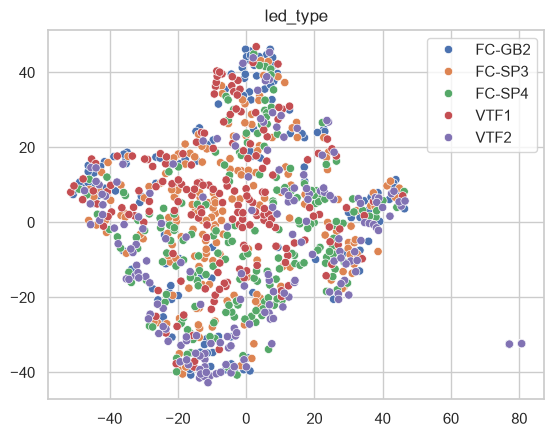

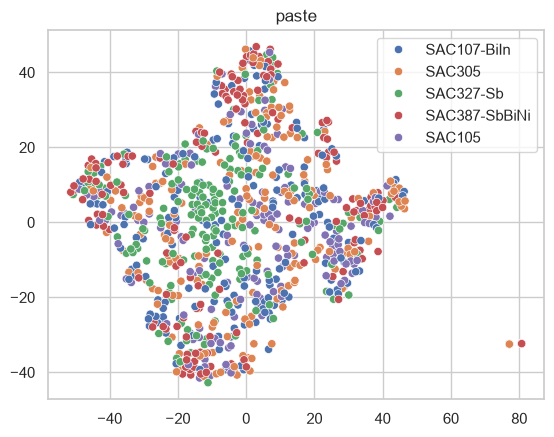

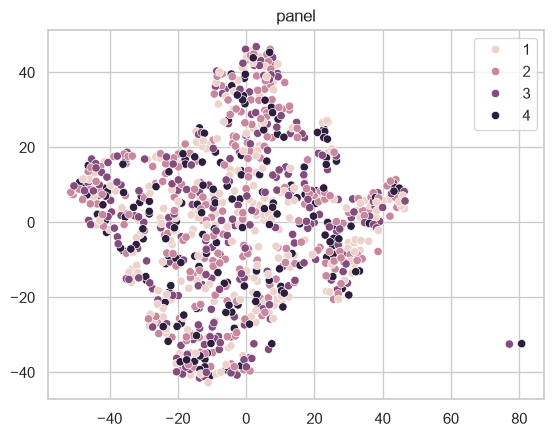

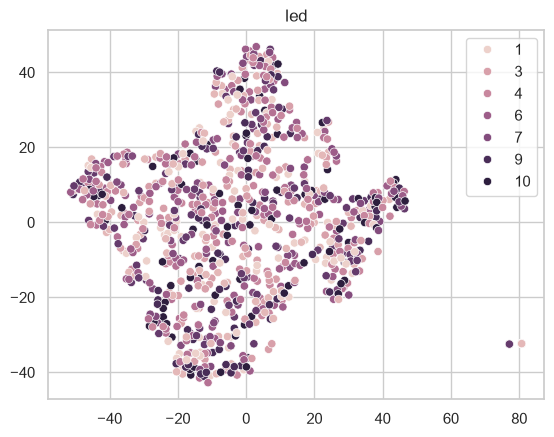

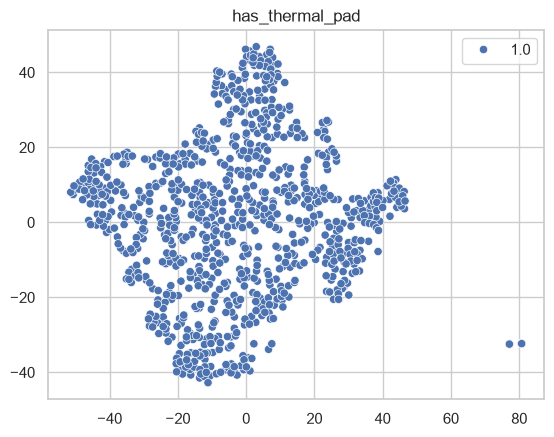

In [132]:
tsne = manifold.TSNE(n_components=2)
X_tsne = tsne.fit_transform(x_th_scaled)
print(X_tsne.shape)
for col in ['led_type', 'paste', 'panel', 'led', 'has_thermal_pad']:
    sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1], hue=therm_df[col])
    plt.legend()
    plt.title(col)
    plt.show()


## PCA

(908, 2)


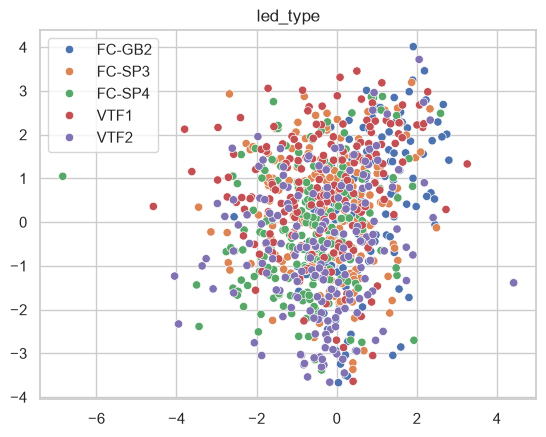

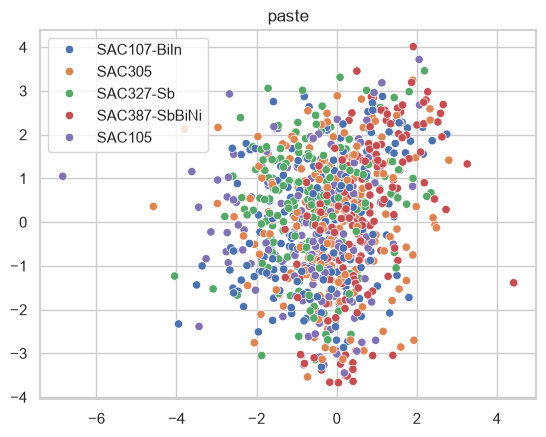

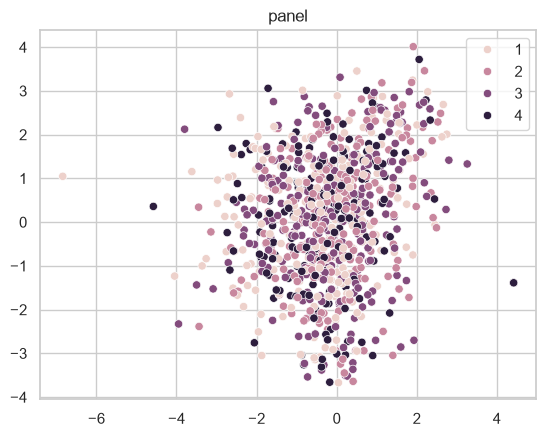

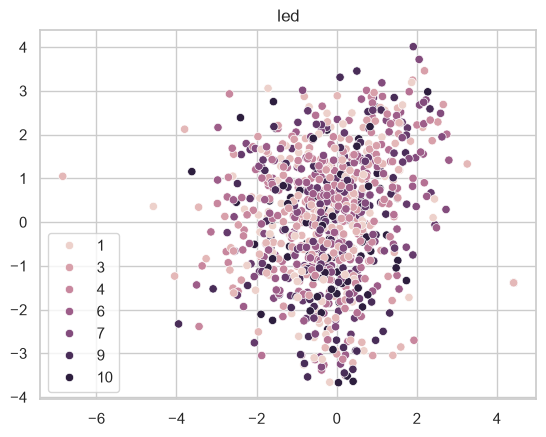

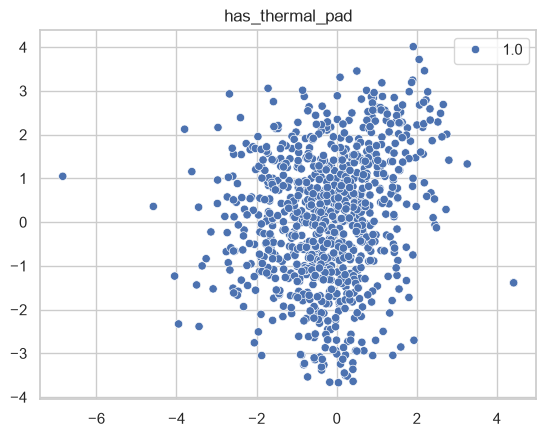

In [133]:
pca_th = PCA(n_components=2)
X_pca_th = pca_th.fit_transform(x_th_scaled)
print(X_pca_th.shape)
for col in ['led_type', 'paste', 'panel', 'led', 'has_thermal_pad']:
    sns.scatterplot(x=X_pca_th[:,0], y=X_pca_th[:,1], hue=therm_df[col])
    plt.legend()
    plt.title(col)
    plt.show()

### KMEANS + PCA + TSNE

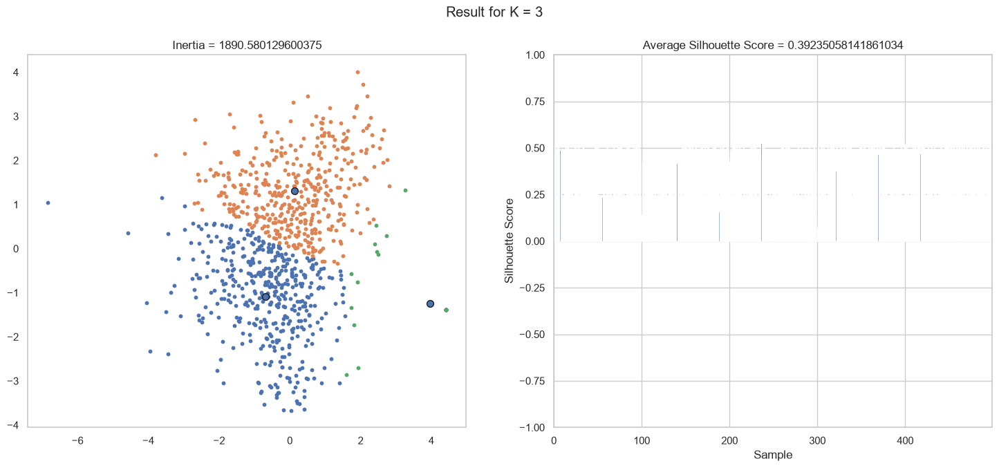

908
(908, 2)


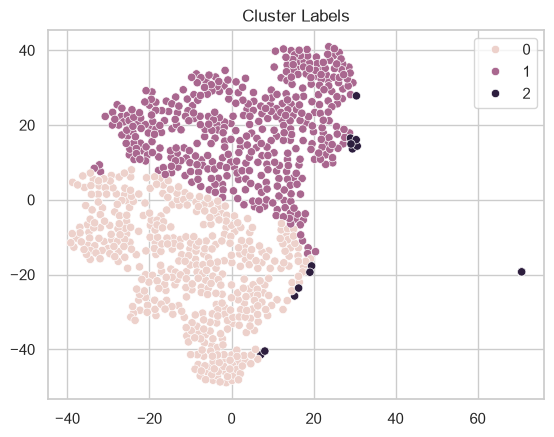

In [251]:
k = 3
kmeans = KMeans(n_clusters=k, random_state=0, n_init=10)
kmeans.fit_transform(X_pca_th)
cluster_labels = kmeans.labels_
centroids = kmeans.cluster_centers_
inertia = kmeans.inertia_
silhouette_values = silhouette_samples(X_pca_th, cluster_labels)
silhouette_avg = silhouette_score(X_pca_th, cluster_labels)

fig, (ax1, ax2) = plt.subplots(1, 2)
fig.set_size_inches(18, 7)
fig.suptitle(f"Result for K = {k}")
for i in range(0,k):
    ax1.scatter(X_pca_th[cluster_labels == i,0], X_pca_th[cluster_labels == i,1], s=10)
ax1.scatter(centroids[:,0],centroids[:,1], s=50, color='b', edgecolor='k')
ax1.set_title(f"Inertia = {inertia}")
ax1.grid()
sample = 0
for i in range(0,k):
    sil = silhouette_values[cluster_labels == i]
    ax2.bar(np.arange(sample,sample + sil.size),sil)
    sample = sample + sil.size
ax2.axis([0, 499, -1, 1])
ax2.set_xlabel('Sample')
ax2.set_ylabel('Silhouette Score')
ax2.set_title(f"Average Silhouette Score = {silhouette_avg}")
plt.show()

print(len(cluster_labels))

tsne = manifold.TSNE(n_components=2, perplexity=50, learning_rate='auto', max_iter=1000)
X_tsne = tsne.fit_transform(X_pca_th)
print(X_tsne.shape)
# for col in cluster_labels:
sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1], hue=cluster_labels)
plt.legend()
plt.title("Cluster Labels")
plt.show()

## Kernel PCA

(908, 2)


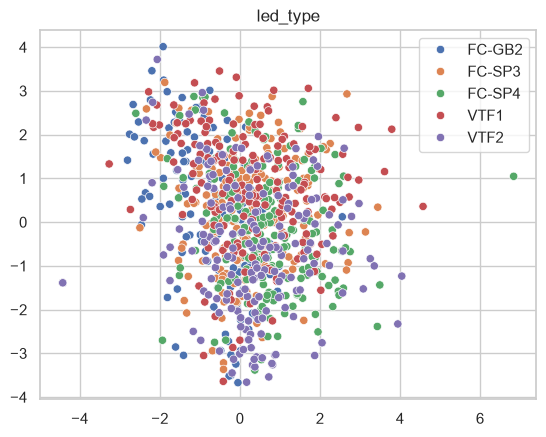

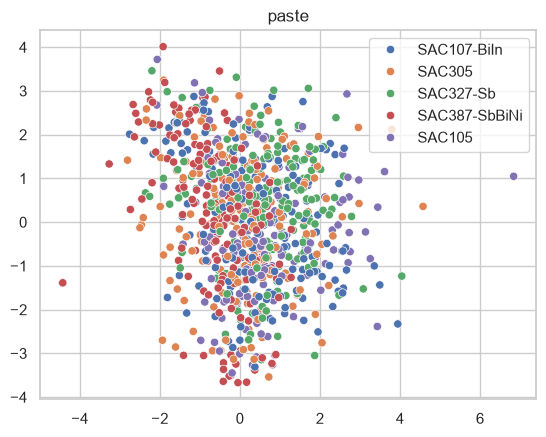

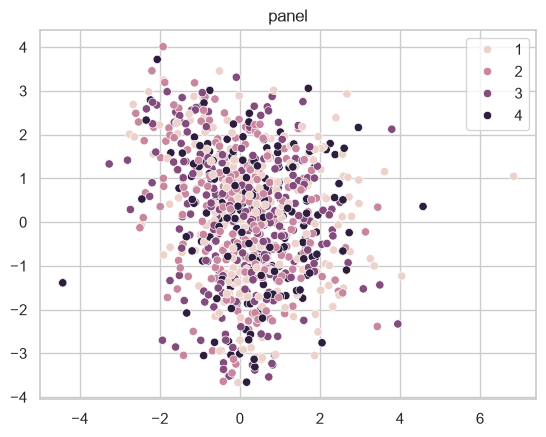

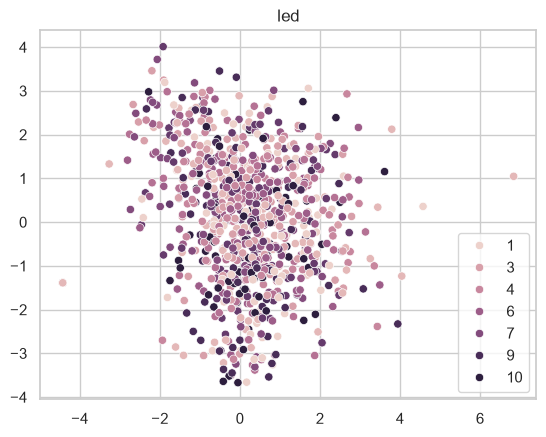

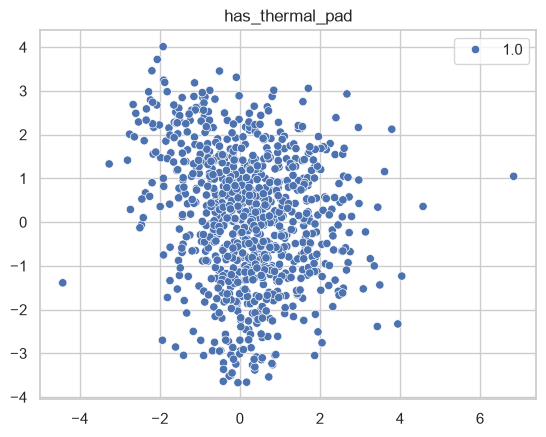

In [134]:
kpca_th = KernelPCA(n_components=2)
X_kpca_th = kpca_th.fit_transform(x_th_scaled)
print(X_kpca_th.shape)
for col in ['led_type', 'paste', 'panel', 'led', 'has_thermal_pad']:
    sns.scatterplot(x=X_kpca_th[:,0], y=X_kpca_th[:,1], hue=therm_df[col])
    plt.legend()
    plt.title(col)
    plt.show()

## Isomap

c:\Users\JPagtalu\Documents\Joanna\MEng AI\ai221\ai221_project\ai221_env\Lib\site-packages\sklearn\manifold\_isomap.py:386: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
c:\Users\JPagtalu\Documents\Joanna\MEng AI\ai221\ai221_project\ai221_env\Lib\site-packages\scipy\sparse\_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


(908, 2)


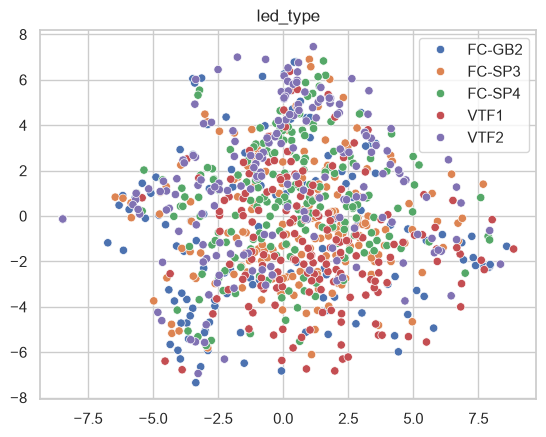

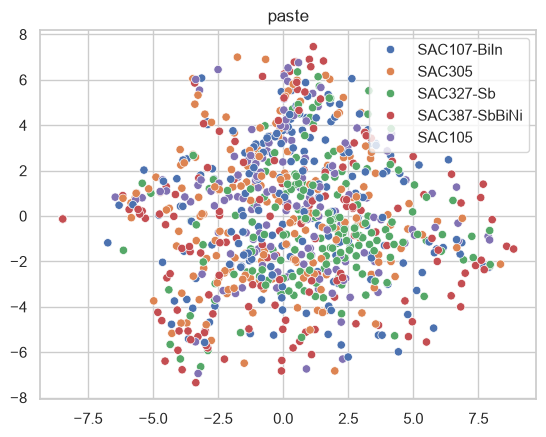

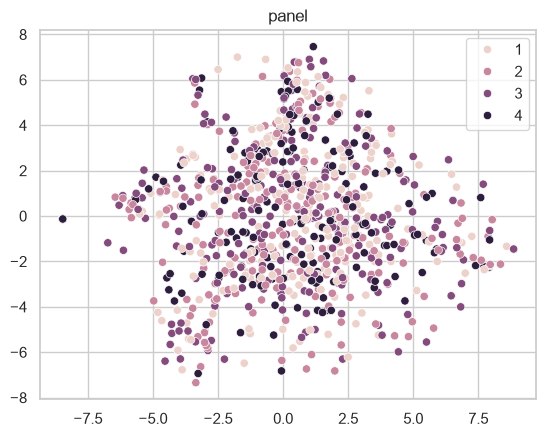

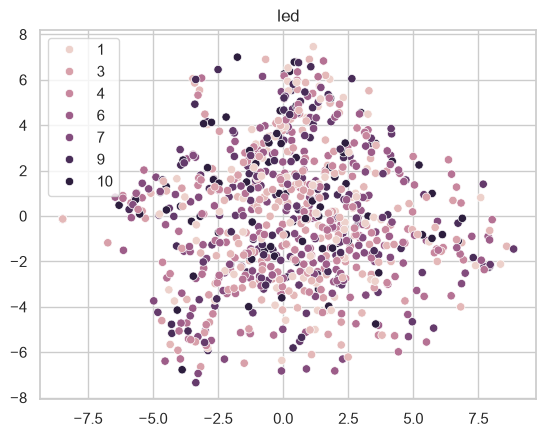

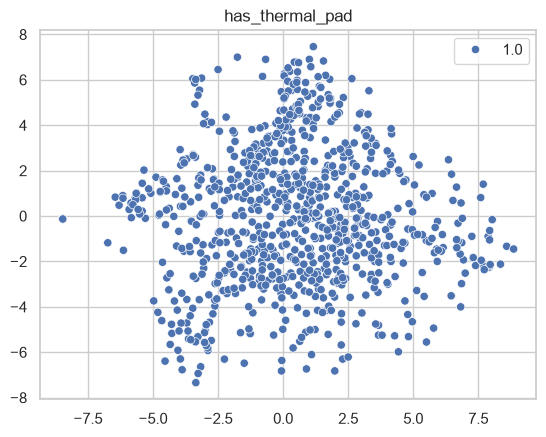

In [135]:
isomap_th = manifold.Isomap(n_components=2)
X_isomap_th = isomap_th.fit_transform(x_th_scaled)
print(X_isomap_th.shape)
for col in ['led_type', 'paste', 'panel', 'led', 'has_thermal_pad']:
    sns.scatterplot(x=X_isomap_th[:,0], y=X_isomap_th[:,1], hue=therm_df[col])
    plt.legend()
    plt.title(col)
    plt.show()

## UMAP

In [136]:
unique_tsc = therm_df["tsc_fail"].dropna().unique()
already_binary = set(unique_tsc).issubset({0, 1, 0.0, 1.0})

if already_binary:
    therm_df["tsc_fail_binary"] = therm_df["tsc_fail"].fillna(0).astype(int)
    print("tsc_fail is already 0/1 — used as-is.")
else:
    # Cycle-number column: NaN = no failure, non-NaN = failure detected
    therm_df["tsc_fail_binary"] = therm_df["tsc_fail"].notna().astype(int)
    print(
        f"tsc_fail contains cycle values {sorted(unique_tsc)[:6]} ...\n"
        "Derived tsc_fail_binary: 1 = failure detected, 0 = no failure."
    )

print(therm_df["tsc_fail_binary"].value_counts().to_string())

tsc_fail contains cycle values [np.float64(100.0), np.float64(150.0), np.float64(250.0), np.float64(350.0), np.float64(500.0), np.float64(750.0)] ...
Derived tsc_fail_binary: 1 = failure detected, 0 = no failure.
tsc_fail_binary
1    687
0    221


c:\Users\JPagtalu\Documents\Joanna\MEng AI\ai221\ai221_project\ai221_env\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


(908, 2)


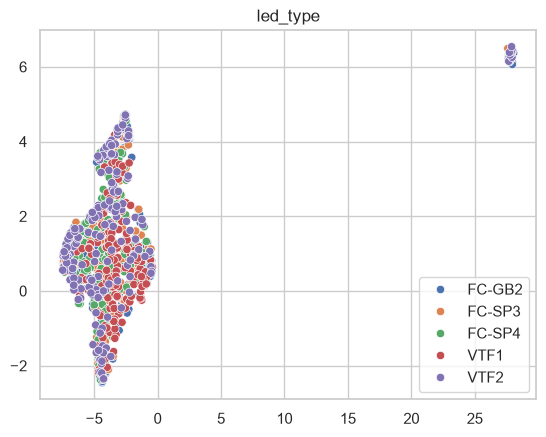

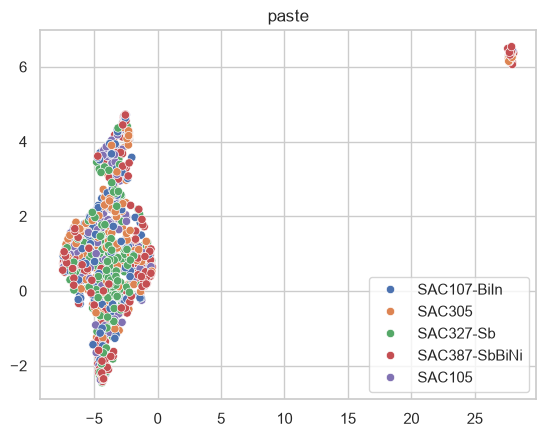

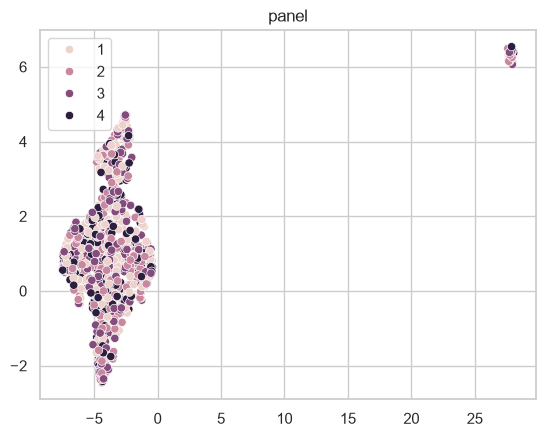

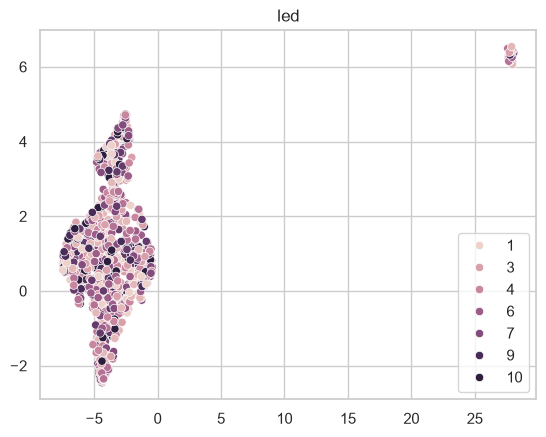

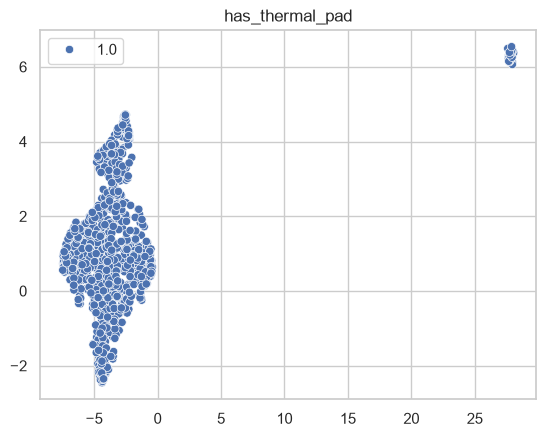

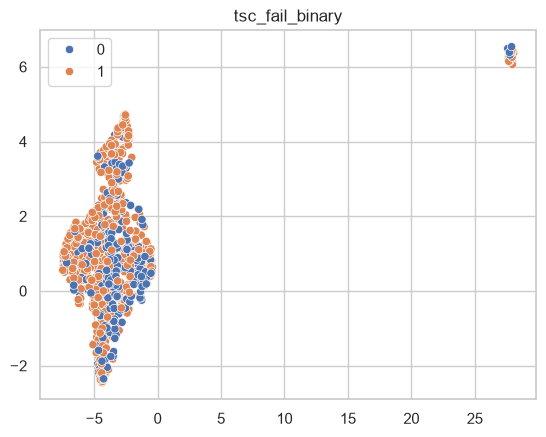

In [255]:
umap_th = umap.UMAP(n_components=2, n_neighbors=150, min_dist=0.1)
X_umap_th = umap_th.fit_transform(x_th_scaled)
print(X_umap_th.shape)
for col in ['led_type', 'paste', 'panel', 'led', 'has_thermal_pad', 'tsc_fail_binary']:
    sns.scatterplot(x=X_umap_th[:,0], y=X_umap_th[:,1], hue=therm_df[col])
    plt.legend()
    plt.title(col)
    plt.show()

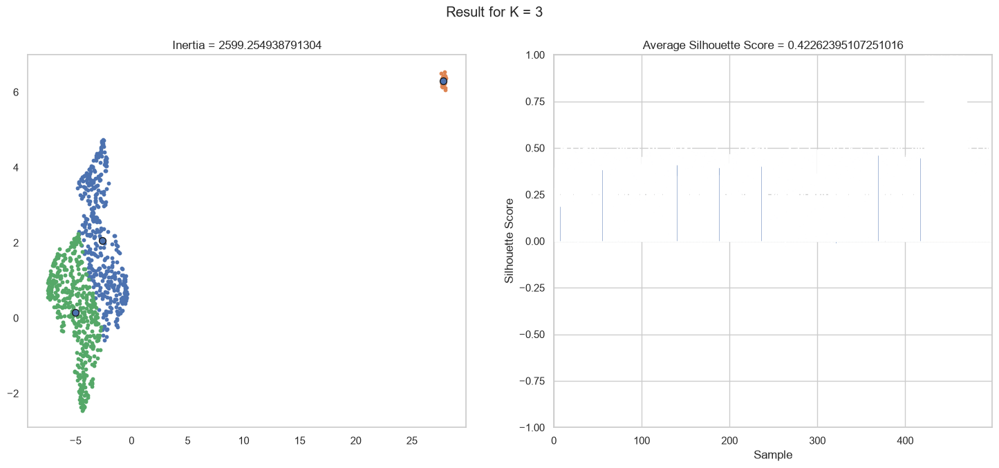

908
(908, 2)


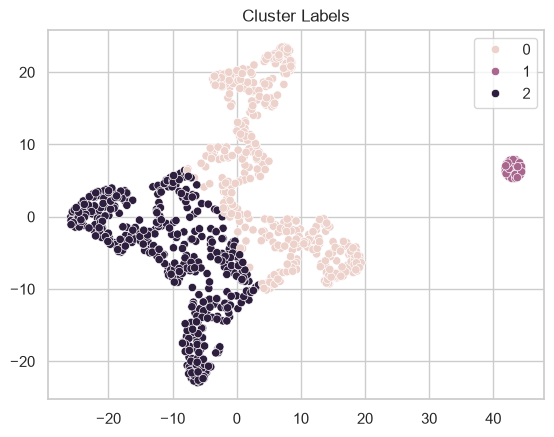

In [256]:
k = 3
kmeans = KMeans(n_clusters=k, random_state=0, n_init=10)
kmeans.fit_transform(X_umap_th)
cluster_labels = kmeans.labels_
centroids = kmeans.cluster_centers_
inertia = kmeans.inertia_
silhouette_values = silhouette_samples(X_umap_th, cluster_labels)
silhouette_avg = silhouette_score(X_umap_th, cluster_labels)

fig, (ax1, ax2) = plt.subplots(1, 2)
fig.set_size_inches(18, 7)
fig.suptitle(f"Result for K = {k}")
for i in range(0,k):
    ax1.scatter(X_umap_th[cluster_labels == i,0], X_umap_th[cluster_labels == i,1], s=10)
ax1.scatter(centroids[:,0],centroids[:,1], s=50, color='b', edgecolor='k')
ax1.set_title(f"Inertia = {inertia}")
ax1.grid()
sample = 0
for i in range(0,k):
    sil = silhouette_values[cluster_labels == i]
    ax2.bar(np.arange(sample,sample + sil.size),sil)
    sample = sample + sil.size
ax2.axis([0, 499, -1, 1])
ax2.set_xlabel('Sample')
ax2.set_ylabel('Silhouette Score')
ax2.set_title(f"Average Silhouette Score = {silhouette_avg}")
plt.show()

print(len(cluster_labels))

tsne = manifold.TSNE(n_components=2, perplexity=50, learning_rate='auto', max_iter=1000)
X_tsne = tsne.fit_transform(X_umap_th)
print(X_tsne.shape)
# for col in cluster_labels:
sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1], hue=cluster_labels)
plt.legend()
plt.title("Cluster Labels")
plt.show()

# No Therm Pad only

In [185]:
elec_pad_indices = []

for i in range(len(data1)):
    # print(i)
    if data1['has_thermal_pad'].iloc[i] == 0:
        elec_pad_indices.append(i)

elec_df = pd.DataFrame(data1.iloc[elec_pad_indices])
elec_df

,unit_id,led_type,paste,panel,led,has_thermal_pad,thermal_void_area_frac,thermal_centroid_x,thermal_centroid_y,thermal_q_NW,...,tsc_fail,tsc_fail_sustained,last_cycle,rth_500,rth_end,rth_increase,rth_increase_pct,ri_500_pct,ri_max_pct,tsc_label
154,FC-GB3_SAC105_P1_L01,FC-GB3,SAC105,1,1,0.0,0.0,0.0,0.0,0.0,...,350.0,350.0,1500.0,15.783736,26.958609,16.561257,159.283424,51.805353,159.283424,3
155,FC-GB3_SAC105_P1_L02,FC-GB3,SAC105,1,2,0.0,0.0,0.0,0.0,0.0,...,350.0,350.0,1500.0,19.683574,36.084295,25.553042,242.640092,86.906291,313.144853,3
156,FC-GB3_SAC105_P1_L03,FC-GB3,SAC105,1,3,0.0,0.0,0.0,0.0,0.0,...,350.0,350.0,1500.0,19.160128,47.828457,37.036281,343.177126,77.537206,343.177126,3
157,FC-GB3_SAC105_P1_L04,FC-GB3,SAC105,1,4,0.0,0.0,0.0,0.0,0.0,...,350.0,350.0,1500.0,18.843722,36.545221,25.923395,244.057779,77.405664,244.057779,3
158,FC-GB3_SAC105_P1_L05,FC-GB3,SAC105,1,5,0.0,0.0,0.0,0.0,0.0,...,350.0,350.0,1500.0,16.183382,26.147072,15.622980,148.449664,53.774615,148.449664,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
711,FC-SP2_SAC387-SbBiNi_P4_L02,FC-SP2,SAC387-SbBiNi,4,2,0.0,0.0,0.0,0.0,0.0,...,1250.0,1250.0,1500.0,6.913846,7.828073,1.647785,26.661943,11.869322,26.661943,2
712,FC-SP2_SAC387-SbBiNi_P4_L03,FC-SP2,SAC387-SbBiNi,4,3,0.0,0.0,0.0,0.0,0.0,...,1500.0,1500.0,1500.0,6.662481,7.469807,1.284322,20.763478,7.711541,20.763478,2
713,FC-SP2_SAC387-SbBiNi_P4_L04,FC-SP2,SAC387-SbBiNi,4,4,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,1500.0,6.348960,6.588931,0.567312,9.421250,5.436079,9.421250,1
714,FC-SP2_SAC387-SbBiNi_P4_L05,FC-SP2,SAC387-SbBiNi,4,5,0.0,0.0,0.0,0.0,0.0,...,1500.0,1500.0,1500.0,6.950245,8.006452,1.999858,33.294374,15.710247,33.294374,2


In [187]:
elec_features = [c for c in elec_df.columns if c.startswith("electrical_")]
x_elec = elec_df[elec_features]

x_elec_scaled = StandardScaler().fit_transform(x_elec)
# x_elec
x_elec_scaled

array([[ 1.98947941, -0.98376789, -0.52526027, ...,  0.11754187,
         1.54702202, -0.85671922],
       [ 3.25682718, -0.10267081,  0.6357736 , ...,  0.16673409,
         2.0623502 , -0.76884793],
       [ 2.27037017, -0.47388963, -0.44535235, ..., -0.32594252,
         0.98559262, -0.67902393],
       ...,
       [-0.66374733, -1.005581  , -1.20165574, ...,  0.48791889,
        -0.63575488, -0.3560804 ],
       [-0.60758346, -0.29075255, -0.70138562, ...,  0.8394209 ,
        -0.68729059, -0.07115937],
       [-0.53043484, -1.37090101, -2.1069936 , ...,  0.51785948,
        -0.64891062, -0.92592246]], shape=(562, 11))

(562, 2)


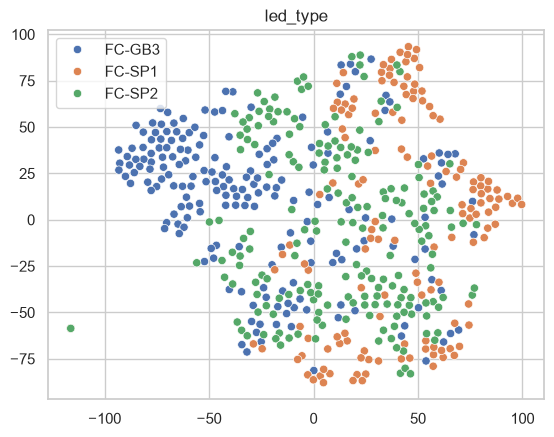

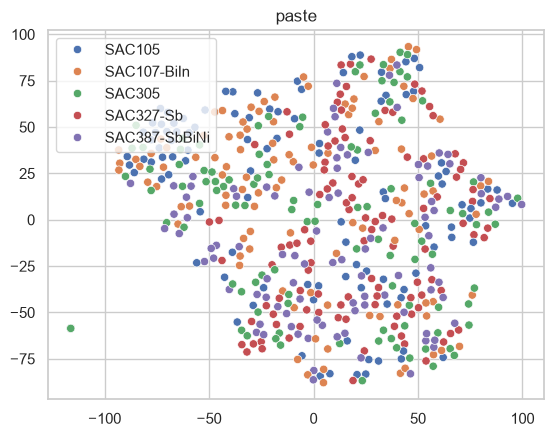

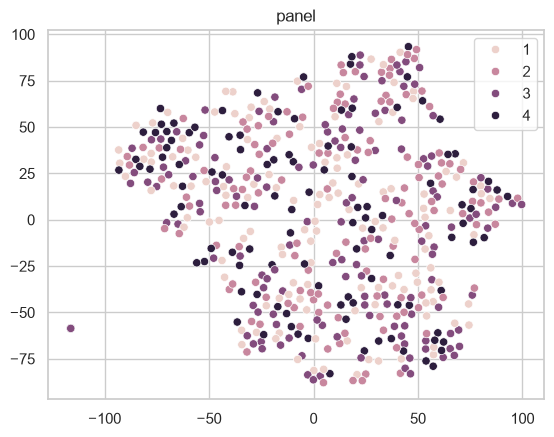

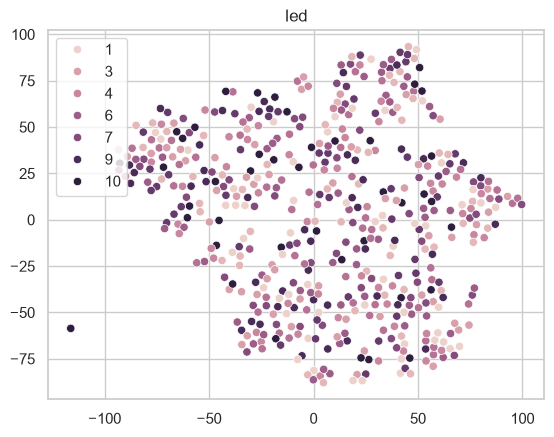

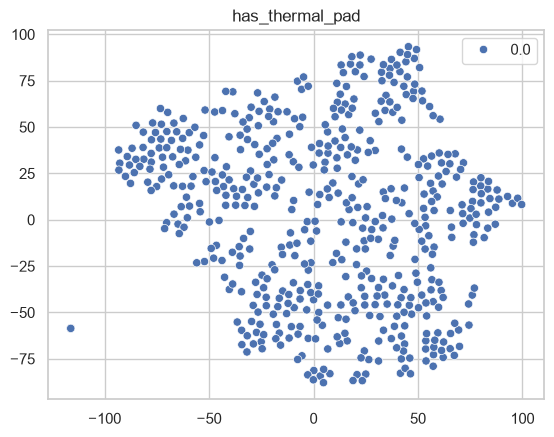

In [189]:
tsne = manifold.TSNE(n_components=2)
X_tsne = tsne.fit_transform(x_elec_scaled)
print(X_tsne.shape)
for col in ['led_type', 'paste', 'panel', 'led', 'has_thermal_pad']:
    sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1], hue=elec_df[col])
    plt.legend()
    plt.title(col)
    plt.show()